# M05b · Fonctions de plusieurs variables et gradient — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m05b_gradient/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M05b.1 à M05b.10, M05b.14, M05b.16 | Les exercices papier (vérification) | ✏️ 🔗 📈 | | |
| A | M05b.18 | Une dérivée partielle par différence centrée · `partial_derivative` | 🔨 | ★ | 20 |
|  | M05b.19 | Dérivée directionnelle et direction de plus grande pente · `directional_derivative, steepest_ascent_direction` | 🔨 | ★★ | 20 |
|  | M05b.20 | Le plan tangent · `tangent_plane` | 🔨 | ★ | 15 |
|  | M05b.21 | SymPy : dérivées partielles, gradient, points critiques | 📦 | ★ | 20 |
| B | M05b.22 | Prédire : la dérivée directionnelle le long d'une ligne de niveau | 🔮 | ★ | 10 |
|  | M05b.23 | L'erreur du plan tangent quand on s'éloigne du point | 🔬 | ★★ | 20 |
|  | M05b.24 | Lignes de niveau et flèches du gradient sur la même figure | 🎨 | ★ | 20 |
| C | M05b.25 | Chasse à l'erreur : la mauvaise variable dérivée, une direction non unitaire | 🐛 | ★ | 15 |
|  | M05b.26 | Vectoriser : une fonction de deux variables sur une grille (`np.meshgrid`) | 🛠️ | ★ | 15 |
|  | M05b.27 | Défi : retrouver une fonction du second degré à partir de son gradient | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : lignes de niveau, dérivées partielles, gradient, dérivée directionnelle, plus grande pente, plan tangent, dérivées secondes, points critiques, pas de descente, argmin sur un segment, gradient d'une loss, lecture d'une carte.
- Écrire les quatre fonctions de `mymath/multivar.py` et les tester, puis utiliser SymPy.
- Prédire la pente le long d'une ligne de niveau, mesurer l'erreur du plan tangent, tracer une carte avec les flèches du gradient, chasser des erreurs, vectoriser une grille, retrouver une fonction à partir de son gradient.

**Rappel express.** $\nabla f = (f_x, f_y)$ ; $D_{\mathbf{u}} f = \nabla f \cdot \mathbf{u}$ avec $\|\mathbf{u}\| = 1$ ; plus grande montée $\frac{\nabla f}{\|\nabla f\|}$, de pente $\|\nabla f\|$ ; plan tangent $z = f(a, b) + f_x\,(x - a) + f_y\,(y - b)$ ; $D = f_{xx}f_{yy} - f_{xy}^2$ : $D > 0$ et $f_{xx} > 0$ minimum, $D > 0$ et $f_{xx} < 0$ maximum, $D < 0$ selle ; descente : $\mathbf{x} - \eta\,\nabla f(\mathbf{x})$.

## Partie 0 · Vérifier tes exercices papier (✏️ M05b.1 à M05b.10, 🔗 M05b.14, 📈 M05b.16)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"7/9"` ; une expression en $x$ et $y$ entre guillemets, `"3*x**2*y - y"`, avec `exp(u)` pour $e^u$ et `sqrt(u)` pour $\sqrt{u}$ ;
- une liste `[-1.5, 2.5]` (un gradient, un point, un vecteur), `True` / `False`, ou une lettre entre guillemets, `"B"`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction

FXX_7 = 6 * 0.25 - 0.25 * math.exp(0.5)                   # M05b.7 at (1, 0.5)
FXY_7 = 3 - math.exp(0.5) - 0.5 * math.exp(0.5)
FYY_7 = 2 - math.exp(0.5)

**Ex M05b.1 — Les lignes de niveau de trois fonctions**

In [3]:
wbm.record("M05b.1a", 3, mistakes={"isole y dans 3x − y + 2 = 5 : attention au signe devant y": -3})
wbm.record("M05b.1b", 3, mistakes={"isole y dans 3x − y + 2 = c : attention au signe devant y": -3})
wbm.record("M05b.1c", 6, mistakes={"la ligne de niveau coupe l'axe des x là où y = 0 : résous l'équation en x jusqu'au bout": 36})
wbm.record("M05b.1d", 2, mistakes={"la ligne de niveau coupe l'axe des y là où x = 0 : résous l'équation en y jusqu'au bout (une racine carrée)": 4, "tu as répondu pour l'autre axe": 6})
wbm.record("M05b.1e", 13, mistakes={"x est au carré dans f₂": 11})
wbm.record("M05b.1f", -2, mistakes={"isole y dans y − x² = −2 : attention au signe": 2})
wbm.record("M05b.1g", True, mistakes={"(−2)² est positif": False})
wbm.record("M05b.1h", False, mistakes={"x² + 9y² est une somme de carrés : quel est son signe ?": True})

WBM_ANSWER {"hash": "47ea0c89c38bd41ae4cf78ee1da441580f26a7c8c383c42f598d1ee2332bcbcb", "id": "M05b.1a", "kind": "int", "magnitude": 0, "mistakes": {"ea4dd0c6deb080e09e9e3f6028165fad81287b19b4cf086bde211c21852b3bf0": "isole y dans 3x − y + 2 = 5 : attention au signe devant y"}, "sign": 1}
📝 Ex M05b.1a : réponse enregistrée (int).
WBM_ANSWER {"hash": "42e6442af2134fa9fc8ca3cb209a7c36ae17381f9b47e02df85495b6f9ea6bb5", "id": "M05b.1b", "kind": "int", "magnitude": 0, "mistakes": {"094d0b91e03efb944af38682c4536eef1a4ea173fd827e6805f4545cf7f4bbc6": "isole y dans 3x − y + 2 = c : attention au signe devant y"}, "sign": 1}
📝 Ex M05b.1b : réponse enregistrée (int).
WBM_ANSWER {"hash": "0d81c4368d8a444752b8644aff817994f07cff145248e88dabc56cc251661d25", "id": "M05b.1c", "kind": "int", "magnitude": 0, "mistakes": {"d9591afbcf9915eb129e8a8afeb183c487f56045364c4fa4200b8de35b7e0c83": "la ligne de niveau coupe l'axe des x là où y = 0 : résous l'équation en x jusqu'au bout"}, "sign": 1}
📝 Ex M05b.1c : r

**Ex M05b.2 — Dérivées partielles**

In [4]:
wbm.record("M05b.2a", "12*x**2*y + 7", kind="expr", variables=("x", "y"), mistakes={"la dérivée de 7x par rapport à x n'est pas nulle": "12*x**2*y", "−y² ne dépend pas de x : sa dérivée par rapport à x est nulle": "12*x**2*y - 2*y + 7"})
wbm.record("M05b.2b", "4*x**3 - 2*y", kind="expr", variables=("x", "y"), mistakes={"7x ne dépend pas de y : sa dérivée par rapport à y est nulle": "4*x**3 - 2*y + 7", "x³ est une constante quand on dérive par rapport à y, mais y, lui, se dérive": "4*x**3*y - 2*y"})
wbm.record("M05b.2c", -17, mistakes={"remplace y par −2, avec son signe": 31})
wbm.record("M05b.2d", 8, mistakes={"remplace y par −2, avec son signe": 0})
wbm.record("M05b.2e", 2, mistakes={"applique la règle de la chaîne : dérive aussi l'exposant 2x − y par rapport à x": 1})
wbm.record("M05b.2f", -1, mistakes={"la dérivée de l'exposant 2x − y par rapport à y est négative": 1})
wbm.record("M05b.2g", 6, mistakes={"z² est positif même si z est négatif": -6})
wbm.record("M05b.2h", -4, mistakes={"z³ garde le signe de z": 4})

WBM_ANSWER {"hash": "b56cf629419054678cfbfb127fb6f458e8c024bc5562da14d575addb38bc0c74", "id": "M05b.2a", "kind": "expr", "mistakes": {"0510e989d003f64002356191aa44b4af5c3c80945a0c14af3be829601418c19f": "la dérivée de 7x par rapport à x n'est pas nulle", "65471d442d6a31fc5544b9b5219675ebb655a3865b6041409fe58ed635b79bcd": "−y² ne dépend pas de x : sa dérivée par rapport à x est nulle"}, "points": [["1/3", "-2/5"], ["5/7", "9/4"], ["6/5", "-7/3"], ["-2/5", "3/11"], ["9/4", "13/6"]], "variables": ["x", "y"]}
📝 Ex M05b.2a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "acb0a69b0b44ddf502424af552c4223b2460c8485cd75881335d40b39bc4cfc3", "id": "M05b.2b", "kind": "expr", "mistakes": {"88e797df798b6cbe206697f8cedaad35a724f07dd585154964a248396a6d3426": "x³ est une constante quand on dérive par rapport à y, mais y, lui, se dérive", "8ab325f26bf6684fc07367f0ab771e6b80c50572cbceefd35b299c9269be8beb": "7x ne dépend pas de y : sa dérivée par rapport à y est nulle"}, "points": [["1/3", "-2/5"], ["5/

**Ex M05b.3 — Le gradient en un point et sa norme**

In [5]:
wbm.record("M05b.3a", [12, 1], mistakes={"∂f/∂y contient aussi la dérivée du terme −3y": [12, 4]})
wbm.record("M05b.3b", 145 ** 0.5, decimals=4, mistakes={"la norme est la racine carrée de la somme des carrés": 145, "la norme n'est pas la somme des composantes": 13})
wbm.record("M05b.3c", [0, -3])
wbm.record("M05b.3d", [-3 ** 0.5, 3 ** 0.5], decimals=3, mistakes={"un nombre positif a deux racines carrées : garde toutes les solutions": [3 ** 0.5]})
wbm.record("M05b.3e", [12 / 145 ** 0.5, 1 / 145 ** 0.5], decimals=4, mistakes={"divise le gradient par sa norme pour obtenir un vecteur unitaire": [12, 1]})
wbm.record("M05b.3f", 8 ** 0.5, decimals=4, mistakes={"la norme est la racine carrée de la somme des carrés": 8})

WBM_ANSWER {"decimals": 0, "element_hashes": ["497e1c183ea72b113db00bbaba99b91c10a56aacc465836396b75697fa3a7c7f", "7556854ab77562a575c354d81b8ef22a4cf11c8226cb434401dbe7229b0b21ca"], "hash": "26ff8d76c94b95a56987b4049228cfbfc490bb9d2e67577401520f959715da0e", "id": "M05b.3a", "integer": true, "kind": "array", "mistakes": {"bf62bdad7796429e4e0b3167a17aafb690ec3a079df693f5c38503b1bf6965b7": "∂f/∂y contient aussi la dérivée du terme −3y"}, "shape": [2]}
📝 Ex M05b.3a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"coarse_any": {"0": ["921d624724b508e7f7dc679dcde12dc7fd13f4189739c16d057d6094b409f450"]}, "coarser": {"1": ["b850502ebb9264576106901f1280d8f53bfe5268e949b98dc17cf3d130c6d2ec"], "2": ["e9ec8bc3b99a34d4cff793a27783b911e715b3c17fe01139d4af79c88664587e"]}, "decimals": 4, "hash": "0284bbd12872882202929d672d39391b1ebb90e37b17893823a720e1c8d10e86", "hash_coarse": "5dad55b4df8cfcdba2f37fb7aaacb6b7a9ebe4f255410bc7038ee444d215e8d5", "id": "M05b.3b", "kind": "float", "magnitude": 1, 

**Ex M05b.4 — La dérivée directionnelle dans plusieurs directions**

In [6]:
wbm.record("M05b.4a", 10, mistakes={"dans la direction (1, 0), c'est la dérivée partielle par rapport à x": -2})
wbm.record("M05b.4b", 2, mistakes={"la direction est (0, −1), pas (0, 1)": -2})
wbm.record("M05b.4c", (70 - 48) / 25, decimals=2, mistakes={"divise le vecteur (7, 24) par sa norme avant le produit scalaire": 22})
wbm.record("M05b.4d", 8 / 2 ** 0.5, decimals=4, mistakes={"divise le vecteur (1, 1) par sa norme avant le produit scalaire": 8})
wbm.record("M05b.4e", (-50 - 24) / 13, decimals=1, mistakes={"la direction va de P vers Q : c'est Q − P": 74 / 13, "divise le vecteur Q − P par sa norme": -74})
wbm.record("M05b.4f", 104 ** 0.5, decimals=3, mistakes={"la norme est la racine carrée de la somme des carrés": 104})
wbm.record("M05b.4g", math.degrees(math.acos(8 / (104 ** 0.5 * 2 ** 0.5))), decimals=2, mistakes={"l'angle est demandé en degrés": math.acos(8 / (104 ** 0.5 * 2 ** 0.5))})

WBM_ANSWER {"hash": "cafe904343a34d64715bf250fc93c402f17ea6c05d338b5c0591ccb3b6813132", "id": "M05b.4a", "kind": "int", "magnitude": 1, "mistakes": {"f4366b4d2a4a074f281e065d14b022fa40808fe917a91a01f9a9bbb0c9197ed6": "dans la direction (1, 0), c'est la dérivée partielle par rapport à x"}, "sign": 1}
📝 Ex M05b.4a : réponse enregistrée (int).
WBM_ANSWER {"hash": "cc996c74177a579fd84b1b089e21f892e51d2df3a0896861dae87077d1740de3", "id": "M05b.4b", "kind": "int", "magnitude": 0, "mistakes": {"06c0d05d1dc205e7ed807b08b577b6d07a8a971c9f54240962fdaf3f48f046e3": "la direction est (0, −1), pas (0, 1)"}, "sign": 1}
📝 Ex M05b.4b : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["d9292c056fef2d2b0f2ff5f05cedf3da2e087842e5f3db595905fa069ee8c5ec"]}, "decimals": 2, "hash": "b2c028bff206e47de23d6a4f46711b21525bcbc84fe6bbebc90742211eff0e4e", "hash_coarse": "e917d6885d6ed811d191133f1c94ca98cdce1f339e4fdbf4e703f848d4494203", "id": "M05b.4c", "kind": "float", "magnitude": -1, "mistakes": {"254d

**Ex M05b.5 — Monter le plus vite : la direction et la valeur de la plus grande pente**

In [7]:
wbm.record("M05b.5a", [-5, -3], mistakes={"le terme xy compte dans les deux dérivées partielles": [-6, -6]})
wbm.record("M05b.5b", 34 ** 0.5, decimals=3, mistakes={"la norme est la racine carrée de la somme des carrés": 34, "la norme n'est pas la somme des valeurs absolues des composantes": 8})
wbm.record("M05b.5c", math.degrees(math.atan2(-3, -5)) % 360, decimals=2, mistakes={"les deux composantes du gradient sont négatives : dans quel quadrant pointe-t-il ?": {math.degrees(math.atan(3 / 5)), 180 - math.degrees(math.atan(3 / 5))}, "donne l'angle entre 0 et 360 degrés": math.degrees(math.atan2(-3, -5)), "l'angle est demandé en degrés": math.atan2(-3, -5) % (2 * math.pi)})
wbm.record("M05b.5d", 18 / 10 ** 0.5, decimals=3, mistakes={"divise le vecteur qui va de P vers O par sa norme": 18, "la direction va de P vers O : c'est O − P": -18 / 10 ** 0.5})
wbm.record("M05b.5e", math.degrees(math.acos(18 / 340 ** 0.5)), decimals=2, mistakes={"l'angle est demandé en degrés": math.acos(18 / 340 ** 0.5)})
wbm.record("M05b.5f", Fraction(-5, 3), kind="fraction", simplified=True, mistakes={"la tangente à l'isotherme est orthogonale au gradient, pas parallèle": "3/5", "attention au signe de la pente": "5/3"})

WBM_ANSWER {"decimals": 0, "element_hashes": ["084160349052cdbf68161cdd38e28be32c721272755b66ab5871672d8e7f1407", "766e80efe3e369ebfab4b4806174da0b37a83596f73579464a351d70883dde8d"], "hash": "d1902b3124d1c6dec14d4a9f758cc42b63f31cf0b8366bd70dda6f4a07f65625", "id": "M05b.5a", "integer": true, "kind": "array", "mistakes": {"cff6f9d26fb09187bcd3aa593a10c8a946a644208113a9406ded60a3051d8e36": "le terme xy compte dans les deux dérivées partielles"}, "shape": [2]}
📝 Ex M05b.5a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"coarse_any": {"0": ["b70e629de95dcf2661734d152fb9ea4fe0b37467cb5547eff226c81660f44321"]}, "coarser": {"1": ["b8f8846f8fa51495ec839300269d2fb26bba5e89d93f2005c73a84fd7896aa44"]}, "decimals": 3, "hash": "d88d7a579c05ec563ef1ca631df535e9d965a45cb68e52a9e08f21ea8f25a6ed", "hash_coarse": "1b28b155cdaf6ab34f5b4b3bf5aed74d727051cb7624a680f91e9de4ac05b94d", "id": "M05b.5b", "kind": "float", "magnitude": 0, "mistakes": {"7949ec468b3388bcf97d3fdd51deaa8eddd7db4d6cd629d56ccec

**Ex M05b.6 — Le plan tangent et l'approximation d'une valeur**

In [8]:
wbm.record("M05b.6a", 18, mistakes={"n'oublie pas la racine carrée de y": 36})
wbm.record("M05b.6b", 12, mistakes={"√y est une constante quand on dérive par rapport à x : elle reste en facteur": 6})
wbm.record("M05b.6c", 9 / 4, decimals=2, mistakes={"x² est une constante quand on dérive par rapport à y : il reste en facteur": 0.25, "la dérivée de √y est 1/(2√y)": 4.5})
wbm.record("M05b.6d", -27, mistakes={"C n'est pas f(3, 4) : développe z = f(3, 4) + A(x − 3) + B(y − 4)": 18})
wbm.record("M05b.6e", 18 + 12 * 0.1 + 2.25 * (-0.1), decimals=3, mistakes={"le déplacement en y est négatif : de 4 à 3,9": 18 + 12 * 0.1 + 2.25 * 0.1})
wbm.record("M05b.6f", 3.1 ** 2 * 3.9 ** 0.5, decimals=4)
wbm.record("M05b.6g", 3.1 ** 2 * 3.9 ** 0.5 - (18 + 12 * 0.1 - 2.25 * 0.1), decimals=4, mistakes={"l'erreur demandée est la valeur exacte moins l'approximation": -(3.1 ** 2 * 3.9 ** 0.5 - (18 + 12 * 0.1 - 2.25 * 0.1))})

WBM_ANSWER {"hash": "86ca8b184b6331491f6a618e1b7e057020c9d0a0925b6a22c79d09652e7e96fe", "id": "M05b.6a", "kind": "int", "magnitude": 1, "mistakes": {"b7e8ac7074b632b2706b282163bd8b0fa5d5ca02796a3fede5c060a73745f89b": "n'oublie pas la racine carrée de y"}, "sign": 1}
📝 Ex M05b.6a : réponse enregistrée (int).
WBM_ANSWER {"hash": "704d86dbd2ddf12ae95891991f52282c5f9a35063900a3fa9d9e5e95a6b76b7a", "id": "M05b.6b", "kind": "int", "magnitude": 1, "mistakes": {"e940e8a18a0a373378012c1f3fa1c8e111c47a66a474525bd275e74c3823b74a": "√y est une constante quand on dérive par rapport à x : elle reste en facteur"}, "sign": 1}
📝 Ex M05b.6b : réponse enregistrée (int).
WBM_ANSWER {"alt_coarse": ["8dc8b278cbdb97a107f446a51c4e8db63f84d52c2e5f30f76c1d0edc93873f67"], "coarse_any": {"0": ["305a6d18eea4c1b6ab779ce9fd7c6323e381deb49cd3a9c58a786965107c70d6"]}, "decimals": 2, "hash": "91829a9524ef3efe17697a7522a7be05fd9dda5073cd7a7e5f53cb4b909f54bb", "hash_coarse": "343dfb9c49c0807b865d6a2e2ba1f40afba4b647156e71

**Ex M05b.7 — Dérivées secondes croisées : le théorème de Schwarz vérifié**

In [9]:
wbm.record("M05b.7a", "6*x**2*y - exp(x*y) - x*y*exp(x*y)", kind="expr", variables=("x", "y"), mistakes={"y e^(xy) est un produit de deux fonctions de y : sa dérivée a deux termes": "6*x**2*y - x*y*exp(x*y)", "y e^(xy) est un produit : il manque un des deux termes de sa dérivée": "6*x**2*y - exp(x*y)"})
wbm.record("M05b.7b", "2*x**3 - x**2*exp(x*y)", kind="expr", variables=("x", "y"), mistakes={"applique la règle de la chaîne à e^(xy), à chacune des deux dérivations": "2*x**3 - x*exp(x*y)", "dérive encore une fois par rapport à y": "2*x**3*y - x*exp(x*y)"})
wbm.record("M05b.7c", 6 * 0.25 - 0.25 * math.exp(0.5), decimals=4)
wbm.record("M05b.7d", 3 - math.exp(0.5) - 0.5 * math.exp(0.5), decimals=4)
wbm.record("M05b.7e", 2 - math.exp(0.5), decimals=4)
wbm.record("M05b.7f", (FXX_7 + 2 * FXY_7 + FYY_7) / 2, decimals=3, mistakes={"la direction est donnée par un vecteur unitaire : u = (1, 1)/√2": FXX_7 + 2 * FXY_7 + FYY_7, "le terme croisé compte deux fois : 2 f_xy u₁ u₂": (FXX_7 + FXY_7 + FYY_7) / 2})
wbm.record("M05b.7g", (FXX_7 - 2 * FXY_7 + FYY_7) / 2, decimals=3, mistakes={"la direction est donnée par un vecteur unitaire : u = (1, −1)/√2": FXX_7 - 2 * FXY_7 + FYY_7, "le terme croisé compte deux fois : 2 f_xy u₁ u₂": (FXX_7 - FXY_7 + FYY_7) / 2, "avec u = (1, −1)/√2, le produit u₁ u₂ est négatif": (FXX_7 + 2 * FXY_7 + FYY_7) / 2})

WBM_ANSWER {"hash": "05aed26aa76160c69724d58a4596c67f9df5409d30c9807096fb9a2a02e446e3", "id": "M05b.7a", "kind": "expr", "mistakes": {"3d099fae44925f226b9fe25f8e0eb8a6cb366fe3b27c3daf1b76bd2dd9ead5dc": "y e^(xy) est un produit : il manque un des deux termes de sa dérivée", "a687997500aeb45f4b01fa2fb0a148f8b6fd50810d9f43e3ce140a4a1c143183": "y e^(xy) est un produit de deux fonctions de y : sa dérivée a deux termes"}, "points": [["1/3", "-2/5"], ["5/7", "9/4"], ["6/5", "-7/3"], ["-2/5", "3/11"], ["9/4", "13/6"]], "variables": ["x", "y"]}
📝 Ex M05b.7a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "3ccbdc2066e79d1e54f0c046f4298d94f80b3d124399fb77d4d37504ec320176", "id": "M05b.7b", "kind": "expr", "mistakes": {"13b9ddd061ff6170a8fe074246beee17fcd01560f0d319ff48367633964cd5a2": "applique la règle de la chaîne à e^(xy), à chacune des deux dérivations", "824a569fc4a9f505f37c19de934958ca4681f64cab5bb9813e2a7ab349df7f77": "dérive encore une fois par rapport à y"}, "points": [["1/3", "-2/5"],

**Ex M05b.8 — Les points critiques et leur nature (test du second ordre)**

In [10]:
wbm.record("M05b.8a", -24, mistakes={"calcule f_xx en (−2, 2), avec son signe": 24})
wbm.record("M05b.8b", "A", mistakes={"regarde le signe de f_xx en ce point": "B", "calcule D = f_xx f_yy − f_xy² en ce point : son signe décide": "C", "D n'est pas nul en ce point : le test conclut": "D", "réponds par une lettre : A, B, C ou D": {"minimum", "maximum", "selle", "point selle", "min", "max"}})
wbm.record("M05b.8c", "C", mistakes={"calcule D = f_xx f_yy − f_xy² en (−2, 2) : son signe passe avant celui de f_xx": {"A", "B"}, "D n'est pas nul en ce point : le test conclut": "D", "réponds par une lettre : A, B, C ou D": {"minimum", "maximum", "selle", "point selle", "min", "max"}})
wbm.record("M05b.8d", -20)
wbm.record("M05b.8e", 4, mistakes={"le système x² + y² = 5, xy = 2 a aussi des solutions négatives": 2})
wbm.record("M05b.8f", 2, mistakes={"calcule D = 36(x² − y²) en chacun des points critiques": {0, 1, 3, 4}})
wbm.record("M05b.8g", 28, mistakes={"c'est la valeur de g en un autre point critique": -28})
wbm.record("M05b.8h", "D", mistakes={"le test ne voit que D et f_xx : calcule D en (0, 0)": {"A", "B", "C"}, "réponds par une lettre : A, B, C ou D": {"minimum", "maximum", "selle", "point selle", "min", "max"}})

WBM_ANSWER {"hash": "6169764dd618c383e42c5032c50d375a12bd9528d82d466ba93b0a8c95a31b79", "id": "M05b.8a", "kind": "int", "magnitude": 1, "mistakes": {"414cdc64a7d34e2c01054c6d3be1fb470b13bfcac34be6bb4efebd1e8d5e8258": "calcule f_xx en (−2, 2), avec son signe"}, "sign": -1}
📝 Ex M05b.8a : réponse enregistrée (int).
WBM_ANSWER {"hash": "110d822fc54c3cd0328764d757457cefa8c26670467a41acf505930148040c1d", "id": "M05b.8b", "kind": "str", "mistakes": {"06460ecfa4306d5a39209983da1aa744418a1960418e2512c2e3ce9e7f552366": "D n'est pas nul en ce point : le test conclut", "327e93c6043dd2b55384cb7f55a90680715d43973407e5c87ce344a0921d07c5": "réponds par une lettre : A, B, C ou D", "4dfaa3033d1cc5a0339045fe55bba4e734814556b3ebb8244cd29a7f612c5732": "réponds par une lettre : A, B, C ou D", "56e1b2b3868e8ded1e161e2d3af4f27daa92671aa80be964f434edc1afc1e527": "regarde le signe de f_xx en ce point", "5be3f5bce4b92e8a2fe964e0a11aae131069fc2a786bc3a3f2926d6d556404fe": "réponds par une lettre : A, B, C ou D", 

**Ex M05b.9 — Pourquoi un petit pas contre le gradient fait baisser f : le calcul au premier ordre**

In [11]:
wbm.record("M05b.9a", [2, 3], mistakes={"∂f/∂y contient aussi la dérivée du terme y²": [2, 1]})
wbm.record("M05b.9b", [1 - 0.05 * 2, 1 - 0.05 * 3], decimals=2, mistakes={"pour descendre, on retire η ∇f(P)": [1 + 0.05 * 2, 1 + 0.05 * 3]})
wbm.record("M05b.9c", 0.9 ** 2 * 0.85 + 0.85 ** 2, decimals=3)
wbm.record("M05b.9d", 2 - 0.05 * 13, decimals=2, mistakes={"la prévision utilise le carré de la norme du gradient": 2 - 0.05 * 13 ** 0.5})
wbm.record("M05b.9e", 2 - (0.9 ** 2 * 0.85 + 0.85 ** 2), decimals=3)
wbm.record("M05b.9f", 1.1 ** 2 * 1.15 + 1.15 ** 2, decimals=3, mistakes={"pour monter, on ajoute η ∇f(P)": 0.9 ** 2 * 0.85 + 0.85 ** 2})
wbm.record("M05b.9g", Fraction(1, 130), kind="fraction", simplified=True, mistakes={"la baisse voulue est 0,1, pas 1": "1/13"})

WBM_ANSWER {"decimals": 0, "element_hashes": ["44c27ce7f089e732b15b60c5c3b1819d82f43cac932998683537941b964f47ad", "68d30ab63ad4ba85b6b72894dd4c2966ee716b1366c9bc34125ef43b0d974caf"], "hash": "276d276710bb31895a48652a196084ad9ffef34885e5e280b063b2ce107b3659", "id": "M05b.9a", "integer": true, "kind": "array", "mistakes": {"a884e00236f622f9d55dfcd8b7104e877f97b3f0ab80129bdf5a7b970ea60d9a": "∂f/∂y contient aussi la dérivée du terme y²"}, "shape": [2]}
📝 Ex M05b.9a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 2, "element_coarse": [["42b04313f6f7a030c04addb9780b8a3f5c62c528287fa38ed8afe48e46b7edcf"], ["94ef65fad7080bbf16b76cf1206b4fe82b302847fe98e6d0a560ad0b76e72d5b", "7cc2dcb52b3eba9000697b3f80f39ceec43d55541bf37a2f0db7d0679cc416fb"]], "element_coarse_any": [["98e8e5469edbf946edadf68fbf35fa525ff27bab80130e1b61e75942a1742e58"], ["09148fefded6c3b231dd20b9e8e81ff15a8eb06ccb06312016112058f6f9990f"]], "element_hashes": ["b8c4be0de1f72490220624e99819246e294adb546d57cf820309

**Ex M05b.10 — argmin et argmax sur un segment**

In [12]:
wbm.record("M05b.10a", 0.4, decimals=1)
wbm.record("M05b.10b", [1.6, 1.2], decimals=1)
wbm.record("M05b.10c", 0.8, decimals=1, mistakes={"c'est la valeur de t ; la question demande la valeur de f": 0.4})
wbm.record("M05b.10d", [4, 0], mistakes={"compare les valeurs de f aux deux extrémités du segment": [0, 2]})
wbm.record("M05b.10e", 8, mistakes={"compare les valeurs de f aux deux extrémités du segment": 4})
wbm.record("M05b.10f", [1, 0])
wbm.record("M05b.10g", -1, mistakes={"refais le calcul de f en ce point, terme par terme": 0})
wbm.record("M05b.10h", 0, mistakes={"refais le produit scalaire, composante par composante": {1, -1}})

WBM_ANSWER {"decimals": 1, "hash": "84e6b4f0bc4a7a2a66983e1c1b62e5ab53664270d3f747443fcded01796e8eb3", "hash_coarse": "d86915fefd8c469ed3fb33b2c14486df392dedad30abda35362b897ac86fb119", "id": "M05b.10a", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex M05b.10a : réponse enregistrée (float, 1 décimale).
WBM_ANSWER {"decimals": 1, "element_hashes": ["5dc49967aa164f28d225ad7af809d1a40702cd70b6173eb101a96431a45ef3c2", "ac31a17a207f97a42eac4177f28d825cb19c6227494c82ade275ac616c9f96ec"], "hash": "26b7bbca22a714b7e35298b61721706a2f1c2f45e84eadb04bb20448db32ae3d", "id": "M05b.10b", "kind": "array", "shape": [2]}
📝 Ex M05b.10b : réponse enregistrée (array, 1 décimale).
WBM_ANSWER {"decimals": 1, "hash": "c0382cf4779036b13aafbf924298c2e445b44aa36812f870457aba89082e36ac", "hash_coarse": "0fac6d2b6a92f7147f451b650db13f73f9ac2f51db2d038b8207c7173d2c5025", "id": "M05b.10c", "kind": "float", "magnitude": -1, "mistakes": {"835f98c651581ce04862d23d3f7e4cca2945b51f2171a1b34e3f71dffa5d67cb": "c'est la 

**Ex M05b.14 — La loss d'un neurone à deux poids sur deux exemples : son gradient**

In [13]:
wbm.record("M05b.14a", 0.625, decimals=3, mistakes={"n'oublie pas le facteur 1/2 devant la somme": 1.25})
wbm.record("M05b.14b", -2.5, decimals=1, mistakes={"le facteur 1/2 de L compense le 2 de la dérivée d'un carré": -5.0})
wbm.record("M05b.14c", 2.0, decimals=1, mistakes={"le facteur 1/2 de L compense le 2 de la dérivée d'un carré": 4.0})
wbm.record("M05b.14d", [0.75, 0.3], decimals=2, mistakes={"pour descendre, on retire η ∇L": [0.25, 0.7]})
wbm.record("M05b.14e", 0.0625, decimals=4)
wbm.record("M05b.14f", [5 / 7, 1 / 7], decimals=4, mistakes={"l'ordre est [w₁, w₂]": [1 / 7, 5 / 7]})

WBM_ANSWER {"alt_coarse": ["54462618d27c78f67c3028a5f74443e25773b0155fa7c171dd34b9bf7adf66ee"], "coarse_any": {"0": ["eef504e08ae4b0a1d58e5416f667b3294d9249cb137313d703fbad5391ab641e"], "1": ["d170e24361ebd58103ce9f2b4f3bf77e97d2964e68f0d2b2b5baba53946592b8"]}, "decimals": 3, "hash": "0df5633b2ab5df980ae3cfc58b4f0856e5953be15edba74c51c51ff40ceca428", "hash_coarse": "3e182b177338ac2158aad1fa9df78e42f4caae28279907bb325e73cd67fa9e25", "id": "M05b.14a", "kind": "float", "magnitude": -1, "mistakes": {"a60f287879280ddd12904bc3f31c259d8131b6bd61e5de779c23c6fb3f5d3056": "n'oublie pas le facteur 1/2 devant la somme"}, "sign": 1}
📝 Ex M05b.14a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"alt_coarse": ["6041d587f558bb45038a76ce1cb29ccae869f6c3dd676e662f5c2f621f6cf4ef"], "decimals": 1, "hash": "67be10f6fc3db92da58d4655b1401a6b1145dbbaf35e5cfad4b9023139da52e8", "hash_coarse": "0d0f5bcc835b1665d5f1836770c3cc000d1aee7ba5744145467ae5bf710c54ab", "id": "M05b.14b", "kind": "float", "magnitud

**Ex M05b.16 — Lire une carte de lignes de niveau : estimer une dérivée partielle**

In [14]:
wbm.record("M05b.16a", 3)
wbm.record("M05b.16b", 6)
wbm.record("M05b.16c", 3)
wbm.record("M05b.16d", 5)
wbm.record("M05b.16e", 2)
wbm.record("M05b.16f", 6, mistakes={"recompte les lignes traversées une à une, en suivant le segment de P à Q": {5, 7}})

WBM_ANSWER {"hash": "f45f195d0d6a6a5d7b76a52232ee8bc0f4844324da4d878e3e16faed44d83a2f", "id": "M05b.16a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M05b.16a : réponse enregistrée (int).
WBM_ANSWER {"hash": "f80da988b4b76f06145bb71cad4e684d56d409a3585b12125d9f9e007f6667b8", "id": "M05b.16b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M05b.16b : réponse enregistrée (int).
WBM_ANSWER {"hash": "38f9915b5c7e42e0b6c00dd49c852951fe9f22a501e036e12500a262091b6d45", "id": "M05b.16c", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M05b.16c : réponse enregistrée (int).
WBM_ANSWER {"hash": "d0d9a9188d1fda2122823ed0514f2a7bbd1cded53fe1dde36310037a1ccc67d0", "id": "M05b.16d", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M05b.16d : réponse enregistrée (int).
WBM_ANSWER {"hash": "4fa1da833b40ebfded73045b7d34d2eca831d3e7c4fb2ba9e987a14356b97c8e", "id": "M05b.16e", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M05b.16e : réponse enregistrée (int).
WBM_ANSWER {"hash": "72f1fdf3b0c966dce82f1526

## Partie A · Ta librairie : dérivées partielles, dérivée directionnelle, plan tangent ; SymPy

Fiche §2 à §7. Les quatre fonctions de `mymath/multivar.py`, puis SymPy en plusieurs variables.

In [15]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M05b.18 — Une dérivée partielle par différence centrée · `partial_derivative` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer une dérivée partielle par une différence centrée, en ne bougeant qu'une coordonnée d'une copie du point.  
**Prérequis :** fiche §2 ; M05a §5 · **mymath :** `multivar.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/multivar.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Une fonction de plusieurs variables prend **un seul** argument, un tableau NumPy `p` (`p[0]` est $x$, `p[1]` est $y$…) : par exemple `lambda p: p[0] ** 2 * p[1]`. NumPy suffit ; SymPy et `numpy.gradient` sont interdits : les tests comparent tes résultats aux dérivées exactes calculées par SymPy, et un test vérifie que tu ne te sers d'aucun des deux. Les nombres renvoyés sont des `float` de Python, les vecteurs des tableaux NumPy.

Écris `partial_derivative(f, point, i, h=1e-5)` (fiche §2) : $\frac{f(\mathbf{p} + h\,\mathbf{e}_i) - f(\mathbf{p} - h\,\mathbf{e}_i)}{2h}$, où $\mathbf{e}_i$ vaut 1 à la place $i$ et 0 ailleurs ; une `ValueError` si `i` n'est pas entre 0 et `len(point) - 1`, ou si $h \le 0$. Le point de l'appelant ne doit pas changer (relis le commentaire `TODO` de la fonction).

La vérification calcule :
- a) `partial_derivative(lambda p: p[0] ** 2 * np.exp(p[1]), (1.5, 0.0), 0)` (6 décimales) ;
- b) la même fonction, avec `i = 1` (6 décimales) ;
- c) `partial_derivative(lambda p: p[0] * p[1] * p[2], (2.0, -1.0, 4.0), 2)` (6 décimales) ;
- d) le nom de l'erreur levée par `partial_derivative(lambda p: p[0] + p[1] + p[2], (1.0, 2.0, 3.0), 3)` ;
- e) le nom de l'erreur levée par `partial_derivative(lambda p: p[0], (1.0, 2.0), 0, h=0)` ;
- f) `partial_derivative(lambda p: np.log(p[0] + p[1] ** 2), (1.0, 2.0), 1)` (4 décimales) ;
- g) le nom du type de `partial_derivative(lambda p: np.sin(p[0]), np.array([0.5]), 0)`, en texte.

Dans ta copie : calcule a), b), c) et f) à la main avec les règles de la fiche. Pourquoi les vérifications de `i` et de `h` doivent-elles passer **avant** tout calcul (regarde d) et e)) ?

In [16]:
mymath = wbm.load_mymath("ref")
partial = mymath.multivar.partial_derivative
print("a)", partial(lambda p: p[0] ** 2 * np.exp(p[1]), (1.5, 0.0), 0),
      " b)", partial(lambda p: p[0] ** 2 * np.exp(p[1]), (1.5, 0.0), 1),
      " c)", partial(lambda p: p[0] * p[1] * p[2], (2.0, -1.0, 4.0), 2))
print("d)", raised(partial, lambda p: p[0] + p[1] + p[2], (1.0, 2.0, 3.0), 3),
      " e)", raised(partial, lambda p: p[0], (1.0, 2.0), 0, h=0),
      " f)", partial(lambda p: np.log(p[0] + p[1] ** 2), (1.0, 2.0), 1),
      " g)", type(partial(lambda p: np.sin(p[0]), np.array([0.5]), 0)).__name__)

a) 3.000000000019653  b) 2.2500000000258424  c) -1.9999999999686933
d) ValueError  e) ValueError  f) 0.8000000000008  g) float


In [17]:
wbm.record("M05b.18a", 3.0, decimals=6,
           mistakes={"une différence avant n'est que d'ordre 1 : la docstring demande une différence centrée":
                         3.00001})
wbm.record("M05b.18b", 2.25, decimals=6,
           mistakes={"une différence avant n'est que d'ordre 1 : la docstring demande une différence centrée":
                         2.2500113})
wbm.record("M05b.18c", -2.0, decimals=6,
           mistakes={"ne bouge que la coordonnée i : les autres restent fixées": 2.0,
                     "les indices de Python commencent à 0 : i = 2 désigne la troisième coordonnée": 8.0})
wbm.record("M05b.18d", "ValueError",
           mistakes={"vérifie i avant de t'en servir : un indice hors de 0, …, len(point) − 1 demande une ValueError":
                         "IndexError",
                     "un point de trois coordonnées a les indices 0, 1 et 2 : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M05b.18e", "ValueError",
           mistakes={"vérifie h avant de diviser : un pas nul ou négatif demande une ValueError": "ZeroDivisionError",
                     "un pas nul est refusé : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError"}})
wbm.record("M05b.18f", 0.8, decimals=4,
           mistakes={"i = 1 désigne la deuxième variable, y : c'est elle qui bouge": 0.2})
wbm.record("M05b.18g", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64",
                     "la docstring demande un float de Python, pas un tableau : f renvoie ici un nombre de NumPy, "
                     "à convertir par float(...)": "ndarray"})

WBM_ANSWER {"coarse_any": {"0": ["8729fff50fca5b895ca8c6a39ba4e676272517b98430150b3088e82c5c769a10"]}, "coarser": {"1": ["d4a5387966337850d0e8b4c4869e27317178b516d58359aa1bf16ff48f3af885"], "2": ["52caa614e3c7ee73cbd3dc64278d90a8296f7b95cef07d7bee6fa582210f841f"], "3": ["6cbe7dc3b7f88a17e48d68c011296d10cf78dd745eecdb4d24424341b4c632a7"], "4": ["27850bc18f67f290e53d2ddd735e0f94680ea7b4ec12f66f3946f2aa14481844"]}, "decimals": 6, "hash": "a67bf18484a488d0ce00a9145b6662c4d93ebec9d153aca4f7900e43f47d0821", "hash_coarse": "6671f9237dd793f8815b96e7036ddfedd52bea9b431031f86746afabcb08dcf3", "id": "M05b.18a", "kind": "float", "magnitude": 0, "mistakes": {"0a06ca9e5a41930f5e0debab23dca0004bd3b73f8d2fe684e16decd1b8240242": "une différence avant n'est que d'ordre 1 : la docstring demande une différence centrée"}, "sign": 1}
📝 Ex M05b.18a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["00b46d9b799f7de2ea7e532bcaef7aa93225247c5544c6ab66817d46c1a9d03e"]}, "coarser": {"1"

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [18]:
run_pytest_group("tests/test_m05b_multivar.py", "test_partial_derivative_ or test_multivar_uses_", impl="ref")

pytest: 14 réussi(s), 30 non sélectionné(s) en 0,24 s


💡 a) $\frac{\partial}{\partial x}\big(x^2 e^y\big) = 2x\,e^y = 3$ en $(1{,}5 ;\ 0)$. b) $x^2 e^y = 2{,}25$. c) $\frac{\partial}{\partial z}(xyz) = xy = -2$. d) et e) Les vérifications passent **avant** tout calcul : sans elles, d) lève une `IndexError` et e) une `ZeroDivisionError`. f) $\frac{\partial}{\partial y}\ln(x + y^2) = \frac{2y}{x + y^2} = \frac{4}{5}$ en $(1, 2)$.

### Ex M05b.19 — Dérivée directionnelle et direction de plus grande pente · `directional_derivative, steepest_ascent_direction` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer la dérivée directionnelle d'une fonction et la direction de plus grande montée, en normalisant les directions et en refusant les cas sans direction.  
**Prérequis :** fiche §3 et §4 ; Ex M05b.18 · **mymath :** `multivar.py` · **Parcours :** C, E

Écris (fiche §3 et §4) :
- `directional_derivative(f, point, direction, h=1e-5)` : la pente de `f` en `point` dans la direction du vecteur `direction`, **divisé d'abord par sa norme** ; une seule différence centrée le long du vecteur unitaire $\mathbf{u}$ suffit, $\frac{f(\mathbf{p} + h\mathbf{u}) - f(\mathbf{p} - h\mathbf{u})}{2h}$ (ou le produit scalaire du gradient avec $\mathbf{u}$) ; une `ValueError` si les longueurs diffèrent, si la direction est le vecteur nul, ou si $h \le 0$ ;
- `steepest_ascent_direction(f, point, h=1e-5)` : le vecteur unitaire $\frac{\nabla f(\mathbf{p})}{\|\nabla f(\mathbf{p})\|}$, en tableau NumPy, avec le gradient calculé par ta fonction `partial_derivative` (une coordonnée à la fois) ; une `ValueError` si la norme du gradient calculé est inférieure à $10^{-8}$ (un point critique n'a pas de direction de plus grande pente ; numériquement, le gradient y est minuscule, pas forcément exactement nul), ou si $h \le 0$.

La vérification calcule, pour $f(x, y) = x^2 y + 2y$ au point $(1, 3)$ :
- a) `directional_derivative(f, (1.0, 3.0), (1, 0))` (4 décimales) ;
- b) `directional_derivative(f, (1.0, 3.0), (2, 2))` (4 décimales) ;
- c) `directional_derivative(f, (1.0, 3.0), (-1, 2))` (4 décimales) ;
- d) `steepest_ascent_direction(f, (1.0, 3.0))` (une liste, 4 décimales) ;
- e) le nom de l'erreur levée par `directional_derivative(f, (1.0, 3.0), (0, 0))` ;

puis :
- f) le nom de l'erreur levée par `steepest_ascent_direction(lambda p: p[0] ** 3 + p[0] ** 2 + p[1] ** 2, (0.0, 0.0))` ;
- g) le nom du type de `steepest_ascent_direction(f, (1.0, 3.0))`, en texte ;
- h) la norme de `steepest_ascent_direction(lambda p: np.exp(p[0] - p[1]) + p[2] ** 2, (0.0, 1.0, 1.5))` (4 décimales).

Dans ta copie : calcule $\nabla f(1, 3)$ à la main, puis a), b) et c). Que représente la direction de c) sur la carte des lignes de niveau de $f$ ? Pourquoi f) n'a-t-il pas de réponse ?

In [19]:
mymath = wbm.load_mymath("ref")
F_19 = lambda p: p[0] ** 2 * p[1] + 2 * p[1]                # noqa: E731 - gradient (2xy, x² + 2) = (6, 3) at (1, 3)
dd, steep = mymath.multivar.directional_derivative, mymath.multivar.steepest_ascent_direction
print("a)", dd(F_19, (1.0, 3.0), (1, 0)), " b)", dd(F_19, (1.0, 3.0), (2, 2)), " c)", dd(F_19, (1.0, 3.0), (-1, 2)))
print("d)", steep(F_19, (1.0, 3.0)), " e)", raised(dd, F_19, (1.0, 3.0), (0, 0)),
      " f)", raised(steep, lambda p: p[0] ** 3 + p[0] ** 2 + p[1] ** 2, (0.0, 0.0)),
      " g)", type(steep(F_19, (1.0, 3.0))).__name__,
      " h)", np.linalg.norm(steep(lambda p: np.exp(p[0] - p[1]) + p[2] ** 2, (0.0, 1.0, 1.5))))

a) 5.9999999999504885  b) 6.363961030686482  c) 0.0
d) [0.89442719 0.4472136 ]  e) ValueError  f) ValueError  g) ndarray  h) 1.0


In [20]:
wbm.record("M05b.19a", 6.0, decimals=4)
wbm.record("M05b.19b", 9 / 2 ** 0.5, decimals=4,
           mistakes={"divise la direction par sa norme avant de dériver": 18.0})
wbm.record("M05b.19c", 0.0, decimals=4)
wbm.record("M05b.19d", [2 / 5 ** 0.5, 1 / 5 ** 0.5], decimals=4,
           mistakes={"divise le gradient par sa norme : la docstring demande un vecteur unitaire": [6.0, 3.0]})
wbm.record("M05b.19e", "ValueError",
           mistakes={"le vecteur nul ne donne aucune direction : lève une ValueError avant de diviser par sa norme":
                         {"aucune", "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError"}})
wbm.record("M05b.19f", "ValueError",
           mistakes={"le gradient est nul en ce point : la docstring demande une ValueError quand la norme du "
                      "gradient calculé est inférieure à 1e-8 (numériquement, elle n'est pas forcément exactement 0)":
                         {"aucune", "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError"}})
wbm.record("M05b.19g", "ndarray",
           mistakes={"la docstring demande un tableau NumPy : np.array(...)": {"list", "tuple"}})
wbm.record("M05b.19h", 1.0, decimals=4,
           mistakes={"divise le gradient par sa norme : la docstring demande un vecteur unitaire":
                         float(np.linalg.norm([math.exp(-1), -math.exp(-1), 3.0]))})

WBM_ANSWER {"coarse_any": {"0": ["7fa08448b102dde981b3f514be13bb2fc0f17d887281f4defc91e1c8d9822799"]}, "coarser": {"1": ["8a932ba48bba5c7bc69d282dda80209bb0bfade63d4f485648f2828f30ac5426"], "2": ["df05a86deb3e7c50c038b6a2a305867ad84f5bda34d16bef6d5b50f08007a55b"]}, "decimals": 4, "hash": "91d63fa120c805156eff23fa3dec622570eab0270235d1a751b3ae2117a5a2c8", "hash_coarse": "3743c883b58a6bb417fb93d81b8a1fa57d03f57fc72c7909e2e9e5075e77f3d2", "id": "M05b.19a", "kind": "float", "magnitude": 0, "sign": 1}
📝 Ex M05b.19a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["6a9932214cc901763887a16b76b5ca4e442433196da712d0d0dcee5f9c50bc2f"]}, "coarser": {"1": ["dbfd76de2f6eecd80206f399108115e577809c7877de10a1582c4dea3fa8daa1"], "2": ["3999ea385fd0550d638c5e9f2e57a70eb21ce06247b6a75aeac8d0b23c5016ca"]}, "decimals": 4, "hash": "593f4d03df6186da8be75623b1c060a773aed9dd6c9c4043a989ecdb75e2f14a", "hash_coarse": "74fe7b4097d11273cefaae4254ae66c5c0e8a562d7afd1e0f4b9ca9b6f70291d", 

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group("tests/test_m05b_multivar.py", "test_directional_derivative_ or test_steepest_ascent_direction_ or test_multivar_uses_", impl="ref")

pytest: 22 réussi(s), 22 non sélectionné(s) en 0,25 s


💡 $\nabla f = (2xy,\ x^2 + 2) = (6, 3)$ en $(1, 3)$. a) $\frac{\partial f}{\partial x} = 6$. b) $\frac{(6, 3) \cdot (2, 2)}{\|(2, 2)\|} = \frac{18}{2\sqrt{2}} \approx 6{,}3640$ (et 18 si l'on oublie de normaliser). c) $(6, 3) \cdot (-1, 2) = 0$ : la direction $(-1, 2)$ est orthogonale au gradient, c'est celle de la ligne de niveau de $f$ qui passe par $(1, 3)$. d) $\frac{(6, 3)}{\sqrt{45}} = \frac{(2, 1)}{\sqrt{5}} \approx (0{,}8944 ;\ 0{,}4472)$. f) Le point $(0, 0)$ est un minimum local de $x^3 + x^2 + y^2$ : le gradient y est nul, aucune direction ne monte plus qu'une autre au premier ordre. Les différences centrées y donnent $(h^2, 0) \approx (10^{-10}, 0)$, pas exactement $(0, 0)$ : d'où la tolérance $10^{-8}$ de la docstring.

### Ex M05b.20 — Le plan tangent · `tangent_plane` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer le plan tangent à une surface en un point, et mesurer l'écart entre la surface et ce plan.  
**Prérequis :** fiche §5 ; Ex M05b.18 · **mymath :** `multivar.py` · **Parcours :** C

Écris `tangent_plane(f, point, h=1e-5)` (fiche §5) : les coefficients $(A, B, C)$ du plan tangent $z = Ax + By + C$ à la surface $z = f(x, y)$ au point $(x_0, y_0)$, avec $A$ et $B$ les deux dérivées partielles (ta fonction `partial_derivative`) et $C$ choisi pour que le plan passe par $(x_0, y_0, f(x_0, y_0))$ ; une `ValueError` si le point n'a pas exactement deux coordonnées, ou si $h \le 0$. Renvoie un tuple de trois `float` de Python.

La vérification calcule :
- a) `tangent_plane(lambda p: p[0] * np.exp(p[1]), (2.0, 0.0))` (une liste, 4 décimales) ;
- b) `tangent_plane(lambda p: np.log(p[0] ** 2 + p[1] ** 2), (1.0, 1.0))` (une liste, 4 décimales) ;
- c) le nom de l'erreur levée par `tangent_plane(lambda p: p[0] + p[1] + p[2], (1.0, 2.0, 3.0))` ;
- d) l'écart entre la surface de a) et son plan tangent au point $(2 ;\ 0{,}1)$, $f - (Ax + By + C)$ (5 décimales) ;
- e) les trois nombres renvoyés en a) sont-ils des `float` de Python ? (`True` ou `False`)

Dans ta copie : écris les deux plans à la main, sous la forme $z = f(x_0, y_0) + \ldots$, puis développés. L'écart de d) est-il positif ou négatif, et que dit son signe sur la surface près du point, dans la direction de $y$ ? Calcule $D = f_{xx}f_{yy} - f_{xy}^2$ en $(2, 0)$ : la surface reste-t-elle du même côté de son plan dans toutes les directions ?

In [22]:
mymath = wbm.load_mymath("ref")
plane = mymath.multivar.tangent_plane
A_20, B_20, C_20 = plane(lambda p: p[0] * np.exp(p[1]), (2.0, 0.0))
print("a)", (A_20, B_20, C_20), " b)", plane(lambda p: np.log(p[0] ** 2 + p[1] ** 2), (1.0, 1.0)),
      " c)", raised(plane, lambda p: p[0] + p[1] + p[2], (1.0, 2.0, 3.0)))
print("d)", 2 * math.exp(0.1) - (A_20 * 2 + B_20 * 0.1 + C_20),
      " e)", all(type(v) is float for v in (A_20, B_20, C_20)))

a) (1.0000000000065512, 2.0000000000242046, -1.3102408047416247e-11)  b) (0.9999999999843466, 0.9999999999843466, -1.306852819408748)  c) ValueError
d) 0.010341836148874961  e) True


In [23]:
wbm.record("M05b.20a", [1.0, 2.0, 0.0], decimals=4,
           mistakes={"C n'est pas f(x₀, y₀) : développe z = f(x₀, y₀) + A (x − x₀) + B (y − y₀)":
                         [1.0, 2.0, 2.0]})
wbm.record("M05b.20b", [1.0, 1.0, math.log(2) - 2], decimals=4,
           mistakes={"C n'est pas f(x₀, y₀) : développe z = f(x₀, y₀) + A (x − x₀) + B (y − y₀)":
                         [1.0, 1.0, math.log(2)]})
wbm.record("M05b.20c", "ValueError",
           mistakes={"un plan tangent est celui d'une surface z = f(x, y) : un point de trois coordonnées demande une "
                      "ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M05b.20d", 2 * math.exp(0.1) - 2.2, decimals=5,
           mistakes={"l'écart demandé est f moins le plan, pas le plan moins f": 2.2 - 2 * math.exp(0.1)})
wbm.record("M05b.20e", True,
           mistakes={"la docstring demande des float de Python : float(...) convertit un nombre de NumPy": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["1740f7cca5e32fbc58a75f5ff7f81a3bd452a9d2734dc4036f58822157f6c4e3"], ["52c2410807cae2a335eb20adfb2f667f2c8a706d8c0f938fe407e9012a83b5ae"], ["b9ed31a95fbebf29f63254179451bb4a2761991831bc77ac34e051df3e5ad031"]], "element_coarse_any": [["d8efa7c07ecd585a82d637e23f50f0d80865efde95ff3a54284ab710014e7251", "1153843e2e85384013d6e0e38215ea4b8cc3404618a2a094af4c55db0180fb00", "5b60ce19e18a76734da1b2a5ec5ffc4b600a0fea3b732db6d795bcbfc0a6726b"], ["83904111df76b3e1f27786f189c403aa3915667b8255d3e802cad34b0ed47d64", "cfb979a30a80755558b8a807c5eb2d741f9a63f42d5a54766017bfbd14d9f1ea", "25bba7a48c6ae077b00c5850db2707714c72430d185489c40f48e7011016e700"], []], "element_hashes": ["d54c2350d5991205f8fd49aeca30f80a3f940dc8f54f55df7f775646c1987f5a", "4f31e95ca624ae3f663211cfc873dbbc2ee5ad2e980f08d4dfc4848ea40b3318", "0d9d64fb4f89d26771ac69c418d3c6461c1fd5717f0cd0c91e553fe62c3a4710"], "hash": "876995ab47ca7b47a60203afc08353b00c157d5883c145601baa4ab8911b1c0d", "id

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_m05b_multivar.py", "test_tangent_plane_ or test_multivar_uses_", impl="ref")

pytest: 10 réussi(s), 34 non sélectionné(s) en 0,23 s


💡 a) $f(2, 0) = 2$, $f_x = e^y = 1$, $f_y = x\,e^y = 2$ : $z = 2 + (x - 2) + 2y$, soit $z = x + 2y$, et $C = 0$. b) $f(1, 1) = \ln 2$, $f_x = \frac{2x}{x^2 + y^2} = 1$, $f_y = 1$ : $z = \ln 2 + (x - 1) + (y - 1)$, donc $C = \ln 2 - 2 \approx -1{,}3069$. d) $2\,e^{0{,}1} \approx 2{,}210342$ contre $2 + 0{,}2 = 2{,}2$ : un écart d'environ $0{,}01034$, positif. Dans la direction de $y$, la tranche $y \mapsto 2e^y$ est convexe ($f_{yy} = 2 > 0$) : la surface est au-dessus de son plan, l'écart valant environ $\frac{1}{2}f_{yy}\,\Delta y^2 = 0{,}01$. Mais $D = 0 \times 2 - 1^2 = -1 < 0$ : dans d'autres directions, comme $(2, -1)$, la surface passe au-dessous de son plan (elle le traverse, comme une selle).

### Ex M05b.21 — SymPy : dérivées partielles, gradient, points critiques 📦 ★ ⏱️ 20 min
**Objectif :** calculer avec SymPy des dérivées partielles, un gradient, les points critiques et la matrice des dérivées secondes d'une fonction de deux variables, et les classer.  
**Prérequis :** fiche §2, §6 et §7 · **Parcours :** C, E

SymPy (M02a, M05a) dérive aussi en plusieurs variables :
- `x, y = sp.symbols("x y")`, puis `sp.diff(k, x)` donne $\frac{\partial k}{\partial x}$, et `sp.diff(k, x, y)` donne $\frac{\partial^2 k}{\partial y\,\partial x}$ ;
- `sp.solve([kx, ky], [x, y], dict=True)` résout le système $\nabla k = \mathbf{0}$ : une liste de dictionnaires `{x: ..., y: ...}` ;
- `sp.hessian(k, (x, y))` donne la matrice des dérivées secondes, `.det()` son déterminant $D$, et `.subs({x: 1, y: 2})` remplace les variables par des nombres.

Avec $k(x, y) = x^2 y + y^2 - y$, calcule :
- a) le nombre de points critiques de $k$ (un entier) ;
- b) la valeur de $k$ en son minimum local (une fraction irréductible, en texte) ;
- c) le déterminant $D$ de la matrice des dérivées secondes en $(1, 0)$ (un entier) ;
- d) $\frac{\partial^2 k}{\partial x\,\partial y}(3, 1)$ (un entier) ;
- e) $\nabla k(2, 1)$ (une liste de 2 entiers) ;
- f) $\frac{\partial k}{\partial y}$ (une expression en $x$ et $y$, en texte).

Dans ta copie : classe les points critiques par le test du second ordre (un tableau : point, $k_{xx}$, $k_{yy}$, $k_{xy}$, $D$, nature). Vérifie a) et c) à la main. Le minimum local est-il global (regarde $k(x, -1)$) ?

In [25]:
x, y = sp.symbols("x y")
k = x ** 2 * y + y ** 2 - y
kx, ky = sp.diff(k, x), sp.diff(k, y)
critical = sp.solve([kx, ky], [x, y], dict=True)
H = sp.hessian(k, (x, y))
for point in critical:
    print(point, "· k =", k.subs(point), "· D =", H.det().subs(point), "· k_xx =", H[0, 0].subs(point))
answer_M05b_21a = len(critical)
answer_M05b_21b = str(k.subs({x: 0, y: sp.Rational(1, 2)}))
answer_M05b_21c = int(H.det().subs({x: 1, y: 0}))
answer_M05b_21d = int(sp.diff(k, x, y).subs({x: 3, y: 1}))
answer_M05b_21e = [int(kx.subs({x: 2, y: 1})), int(ky.subs({x: 2, y: 1}))]
answer_M05b_21f = str(ky)
print(answer_M05b_21a, answer_M05b_21b, answer_M05b_21c, answer_M05b_21d, answer_M05b_21e, answer_M05b_21f)

{x: -1, y: 0} · k = 0 · D = -4 · k_xx = 0
{x: 0, y: 1/2} · k = -1/4 · D = 2 · k_xx = 1
{x: 1, y: 0} · k = 0 · D = -4 · k_xx = 0
3 -1/4 -4 6 [4, 5] x**2 + 2*y - 1


In [26]:
wbm.record("M05b.21a", 3,
           mistakes={"compte toutes les solutions que renvoie sp.solve, une par dictionnaire": {1, 2}})
wbm.record("M05b.21b", "-1/4", kind="fraction", simplified=True,
           mistakes={"attention au signe": "1/4", "c'est la valeur de k en un point selle": "0"})
wbm.record("M05b.21c", -4,
           mistakes={"D = k_xx k_yy − k_xy², avec le carré de k_xy": 4})
wbm.record("M05b.21d", 6)
wbm.record("M05b.21e", [4, 5],
           mistakes={"l'ordre est [∂k/∂x, ∂k/∂y]": [5, 4]})
wbm.record("M05b.21f", "x**2 + 2*y - 1", kind="expr", variables=("x", "y"),
           mistakes={"c'est ∂k/∂x ; la question demande ∂k/∂y": "2*x*y"})

WBM_ANSWER {"hash": "2a4b83a0bd73eadee6a7def14e4c16fe97aa09c019b554af8557908bd0fa00dd", "id": "M05b.21a", "kind": "int", "magnitude": 0, "mistakes": {"0d153514c3e3f4f70060e4e0dadc876a54019962f09faf4e625c808888010101": "compte toutes les solutions que renvoie sp.solve, une par dictionnaire", "d267c9dc8f4860265b59c57c1f779db9785a95a52b68377b4996964ef685a568": "compte toutes les solutions que renvoie sp.solve, une par dictionnaire"}, "sign": 1}
📝 Ex M05b.21a : réponse enregistrée (int).
WBM_ANSWER {"hash": "5210a3893e8d9d1b08c261e5479562660acdaa775a28936ca2d294c9fa3f3895", "id": "M05b.21b", "kind": "fraction", "mistakes": {"0025ddd2ec837e5b6a57b8ce6b2165104d9cf12444b027934810e47b33b6ee38": "c'est la valeur de k en un point selle", "203ca7614125428eb1dcf50dd742279cce39aa0b28f1035bf1c6441e259fe382": "attention au signe"}, "sign": -1, "simplified": true}
📝 Ex M05b.21b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "0c213c1441a17340ecfe00938e45c29db5a6a6ca96706b22aa2b9cd9d22982c3", "id

💡 $\nabla k = (2xy,\ x^2 + 2y - 1)$ s'annule si $x = 0$ et $y = \frac{1}{2}$, ou si $y = 0$ et $x = \pm 1$ : trois points critiques. La matrice des dérivées secondes est $\begin{pmatrix} 2y & 2x \\ 2x & 2 \end{pmatrix}$ : en $(0, \frac{1}{2})$, $D = 2 > 0$ et $k_{xx} = 1 > 0$, un minimum local, où $k = \frac{1}{4} - \frac{1}{2} = -\frac{1}{4}$ ; en $(\pm 1, 0)$, $D = 0 \times 2 - 4 = -4 < 0$, deux points selles. Le minimum n'est pas global : $k(x, -1) = 2 - x^2$ tend vers $-\infty$.

## Partie B · Une prédiction, une expérience et une figure

Fiche §1, §4 et §5. La pente le long d'une ligne de niveau, l'erreur du plan tangent, la carte des lignes de niveau avec les flèches du gradient.

### Ex M05b.22 — Prédire : la dérivée directionnelle le long d'une ligne de niveau 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir la pente d'une fonction le long d'une ligne de niveau et le long du gradient, puis le vérifier.  
**Prérequis :** fiche §3 et §4 · **Parcours :** C, E

Soit $f(x, y) = x^2 + 3y^2$ et le point $P = (3, 1)$, où $f(P) = 12$ et $\nabla f(P) = (6, 6)$. On note $\mathbf{u} = \frac{(1, -1)}{\sqrt{2}}$, la direction de la ligne de niveau 12 en $P$. Choisis, pour chaque question :
- a) la dérivée directionnelle de $f$ en $P$ dans la direction $\mathbf{u}$ : (1) positive ; (2) nulle ; (3) négative ; (4) cela dépend du sens de $\mathbf{u}$ ;
- b) en avançant de 0,5 depuis $P$, en ligne droite dans la direction $\mathbf{u}$, $f$ : (1) reste exactement égale à 12 ; (2) augmente un peu ; (3) diminue un peu ; (4) ne peut pas se prévoir ;
- c) la dérivée directionnelle de $f$ en $P$ dans la direction du gradient : (1) 0 ; (2) $\|\nabla f(P)\| \approx 8{,}49$ ; (3) 1 ; (4) 6 ;
- d) combien de directions (vecteurs unitaires) donnent une dérivée directionnelle nulle en $P$ : (1) aucune ; (2) exactement une ; (3) exactement deux ; (4) une infinité.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience. Elle utilise la fonction `directional_derivative` de la référence (la tienne, M05b.19, fait la même chose).

In [27]:
wbm.record("M05b.22a", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M05b.22b", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M05b.22c", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M05b.22d", 3, prediction=True, choices=[1, 2, 3, 4])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "10877a9b05f41bc31bb4902984bdb1a022fe0b56089bad5934f26121ce16438d", "id": "M05b.22a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M05b.22a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "5f666342725a0ff06b14b8f3951d127dbc2ea16f0bd15ed9ac40b4eb3c70465c", "id": "M05b.22b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M05b.22b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "44f02ea31173fa8f0f33b798ccd02dafb5f1a22dcb5b23cd16e048c578eaae53", "id": "M05b.22c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M05b.22c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "b55996e7ec0d336dded005e96717dd37083402a7338c88262100efe605fc8103", "id": "M05b.22d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M05b.22d : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

In [28]:
ref_22 = wbm.load_mymath("ref")                        # the reference library: the same results as yours
f_22 = lambda p: p[0] ** 2 + 3 * p[1] ** 2          # noqa: E731
P_22 = np.array([3.0, 1.0])
grad_22 = np.array([2 * P_22[0], 6 * P_22[1]])            # (6, 6)
tangent_22 = np.array([1.0, -1.0]) / math.sqrt(2)          # orthogonal to the gradient
print("a) slope along the level line:", round(ref_22.multivar.directional_derivative(f_22, P_22, tangent_22), 6) + 0.0)
print("b) f(P) =", f_22(P_22), "· f(P + 0.5 u) =", f_22(P_22 + 0.5 * tangent_22))
print("c) slope along the gradient:", round(ref_22.multivar.directional_derivative(f_22, P_22, grad_22), 6),
      "· ||grad f|| =", round(float(np.linalg.norm(grad_22)), 6))
angles_22 = np.linspace(0, 2 * np.pi, 3601)[:-1]
slopes_22 = grad_22[0] * np.cos(angles_22) + grad_22[1] * np.sin(angles_22)
print("d) angles (in degrees) where the slope is zero:",
      np.degrees(angles_22[np.isclose(slopes_22, 0, atol=1e-9)]).round(1))

a) slope along the level line: 0.0
b) f(P) = 12.0 · f(P + 0.5 u) = 12.500000000000002
c) slope along the gradient: 8.485281 · ||grad f|| = 8.485281
d) angles (in degrees) where the slope is zero: [135. 315.]


**Après l'expérience**, dans ta copie : pourquoi la pente est-elle nulle dans la direction de la ligne de niveau, alors que $f$ augmente quand on avance en ligne droite (calcule $f(P + t\,\mathbf{u})$ en fonction de $t$) ? Dessine l'ellipse $x^2 + 3y^2 = 12$, sa tangente en $P$ et le gradient. Que deviennent ces réponses pour une fonction affine ?

💡 a) $\nabla f(P) \cdot \mathbf{u} = \frac{6 - 6}{\sqrt{2}} = 0$ : la direction de la ligne de niveau est orthogonale au gradient, et ce dans les deux sens. b) $f(P + t\,\mathbf{u}) = 12 + 0 \times t + 2t^2$ : la pente est nulle, mais la droite tangente sort de l'ellipse, vers des valeurs plus grandes (la surface est un bol) ; en $t = 0{,}5$, $f = 12{,}5$. c) La pente dans la direction du gradient est la plus grande, $\|\nabla f(P)\| = 6\sqrt{2} \approx 8{,}49$. d) Les deux vecteurs unitaires orthogonaux au gradient, $\pm\mathbf{u}$ : la pente $\|\nabla f\|\cos\theta$ ne s'annule que pour $\theta = \pm 90°$.

### Ex M05b.23 — L'erreur du plan tangent quand on s'éloigne du point 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer comment l'écart entre une surface et son plan tangent grandit avec la distance au point, et selon la direction.  
**Prérequis :** fiche §5 ; Ex M05b.20 ; M05a §3 · **Parcours :** C

La fiche (§5) annonce que l'erreur de l'approximation par le plan tangent est d'ordre 2 : elle se comporte comme le carré de la distance au point. Vérifie-le.

Écris `plane_error(f, point, direction, r)`, qui renvoie l'écart, en valeur absolue, entre $f$ et son plan tangent en `point` (ta fonction `mymath.multivar.tangent_plane` : écris d'abord M05b.20), au point situé à la distance `r` de `point` dans la direction du vecteur `direction` (à normaliser), en `float`.

La vérification prend $f(x, y) = e^{x - y}$, dont le plan tangent en $(0, 0)$ est $z = 1 + x - y$, et calcule :
- a) l'erreur dans la direction $(1, 0)$, à la distance $r = 0{,}1$ (6 décimales) ;
- b) le rapport des erreurs pour $r = 0{,}2$ et $r = 0{,}1$, dans la direction $(1, 0)$ (2 décimales) ;
- c) la pente de la droite qui ajuste $\ln(\text{erreur})$ en fonction de $\ln r$, pour $r = 0{,}01$ ; 0,02 ; 0,04 ; 0,08 dans la direction $(1, 0)$, par `np.polyfit` (2 décimales) ;
- d) l'erreur dans la direction $(1, 1)$, à la distance $r = 0{,}5$ (6 décimales) ;
- e) l'erreur dans la direction $(1, -1)$, à la distance $r = 0{,}1$ (6 décimales).

Dans ta copie : que dit c) de l'ordre de l'erreur ? Que vaut d), et pourquoi, même loin du point (regarde $f$ le long de la droite $y = x$) ? Compare e) et a) avec le terme d'ordre 2 de Taylor, $\frac{s^2}{2}$, où $s = x - y$ au point d'arrivée.

In [29]:
def plane_error(f, point, direction, r):
    """|f(q) - plane(q)| where q is at distance r from point in the direction of the vector direction, and plane is
    the tangent plane of f at point (mymath.multivar.tangent_plane)."""
    p = np.array(point, dtype=float)
    u = np.array(direction, dtype=float)
    u = u / np.linalg.norm(u)
    q = p + r * u
    a, b, c = mymath.multivar.tangent_plane(f, p)
    return float(abs(f(q) - (a * q[0] + b * q[1] + c)))


F_23 = lambda p: math.exp(p[0] - p[1])                  # noqa: E731
for direction in [(1, 0), (0, 1), (1, 1), (1, -1)]:
    print(direction, [f"{plane_error(F_23, (0.0, 0.0), direction, r):.3e}" for r in (0.1, 0.2, 0.4)])
rs_23 = np.array([0.01, 0.02, 0.04, 0.08])
print("slope:", np.polyfit(np.log(rs_23), np.log([plane_error(F_23, (0.0, 0.0), (1, 0), r) for r in rs_23]), 1)[0])

(1, 0) ['5.171e-03', '2.140e-02', '9.182e-02']
(0, 1) ['4.837e-03', '1.873e-02', '7.032e-02']
(1, 1) ['0.000e+00', '0.000e+00', '0.000e+00']
(1, -1) ['1.049e-02', '4.405e-02', '1.950e-01']
slope: 2.0111414950604076


In [30]:
wbm.record("M05b.23a", 0.0051709181, decimals=6,
           mistakes={"l'erreur est l'écart entre f et son plan tangent, pas entre f et f(point)": 0.1051709181})
wbm.record("M05b.23b", 4.1390634791, decimals=2)
wbm.record("M05b.23c", 2.0111414941, decimals=2)
wbm.record("M05b.23d", 0.0, decimals=6)
wbm.record("M05b.23e", 0.0104885539, decimals=6,
           mistakes={"divise la direction par sa norme : le point est à la distance r du point de départ":
                         0.0214027582})

WBM_ANSWER {"coarse_any": {"2": ["919299c01174e2afc97ab3bf47605e044904111fa5de0207f9c64a6dee0f8fb8"], "3": ["836934e0b7d66676d542737b922742e67df61355bf91478421919bc36b93fabe"]}, "coarser": {"4": ["cbc20f961b4f1fd9ca31c6884ebde7a8cb9f69956dc3a4080c6cc1c11f8938c0"]}, "decimals": 6, "hash": "da23590f3cb18e49ca8da8607507f7107b9a88c4f360aad68e3c2523ac05e498", "hash_coarse": "8cf03369948a33a0a25e4617fd775b13c104fe9f9514fc6ed17fd1e9d5a29060", "id": "M05b.23a", "kind": "float", "magnitude": -3, "mistakes": {"f46d75d2547f6925dad94d0e94405639268771acd8d5ae417b6aa23b07158c74": "l'erreur est l'écart entre f et son plan tangent, pas entre f et f(point)"}, "sign": 1}
📝 Ex M05b.23a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["5d102a368e54c73ca37d8fe161473f6a0e444b15cc9170e9d896a4c960620aa9"]}, "decimals": 2, "hash": "764d4c2f4633ad166735f907bcc2e7c006d6124653108a34316e0310952f4d03", "hash_coarse": "ea97bd5805c1dcdaf06ee2645a46d27a54d1a85500b7b0b0baf342d67673ab16", "id

💡 a) $e^{0{,}1} - 1{,}1 \approx 0{,}005171$. b) et c) Doubler la distance multiplie l'erreur par environ 4 : elle est d'ordre 2 ($r^2$), comme le terme $\frac{s^2}{2}$ de Taylor, avec $s = x - y$. d) Le long de la droite $y = x$, $f = e^0 = 1$ et le plan vaut $1 + x - x = 1$ : la surface et le plan s'y confondent. e) Dans la direction $(1, -1)$, $s = r\sqrt{2}$ est le plus grand possible à distance $r$ : $e^{s} - 1 - s \approx \frac{s^2}{2} = r^2 = 0{,}01$ (exactement $0{,}010489$), deux fois l'erreur de a) environ.

### Ex M05b.24 — Lignes de niveau et flèches du gradient sur la même figure 🎨 ★ ⏱️ 20 min
**Objectif :** tracer une carte de lignes de niveau et les flèches du gradient, et voir qu'elles coupent les lignes à angle droit et s'allongent là où les lignes se serrent.  
**Prérequis :** fiche §1 et §4 ; R0 (matplotlib) · **Parcours :** C, E

Écris `draw_gradient_map(ax, f, grad, xlim, ylim)`, qui dessine dans l'axe `ax`, sur le rectangle $[x_{\min}, x_{\max}] \times [y_{\min}, y_{\max}]$ donné par `xlim` et `ylim` :
- au moins 5 lignes de niveau de `f` (`ax.contour(X, Y, Z, levels=...)`, sur une grille fine faite par `np.meshgrid`), avec leurs valeurs (`ax.clabel`) ;
- les flèches du gradient sur une grille plus grossière, d'au moins 20 points répartis sur tout le rectangle (`ax.quiver(X, Y, U, V)`, où `U` et `V` sont les deux composantes du gradient) ;
- la même échelle sur les deux axes (`ax.set_aspect("equal")`) : sans elle, un cercle paraît ovale, et l'angle entre une flèche et une ligne de niveau est déformé.

Ici, `f(x, y)` et `grad(x, y)` prennent **deux** arguments, qui peuvent être des tableaux : `f` renvoie un tableau de valeurs, et `grad` un couple de tableaux `(U, V)`.

Puis trace la carte de $f(x, y) = \sin x + \cos y$, de gradient $(\cos x, -\sin y)$, sur $[-4, 4] \times [-4, 4]$.

Dans ta copie : repère sur ta figure les maxima, les minima et les points selles de $f$ (que font les flèches autour de chacun ?). Où les flèches sont-elles les plus longues, et que font les lignes de niveau à cet endroit ?

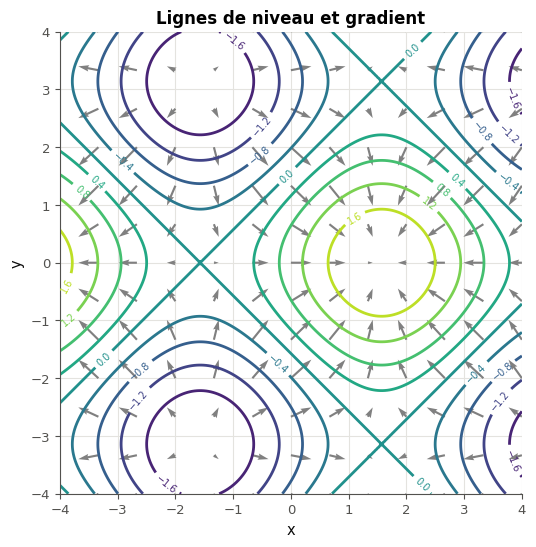

In [31]:
def draw_gradient_map(ax, f, grad, xlim, ylim):
    """In ax, on the rectangle xlim × ylim: at least 5 level lines of f with their values, the arrows of grad on a
    coarser grid (at least 20 points), and the same scale on both axes."""
    X, Y = np.meshgrid(np.linspace(*xlim, 200), np.linspace(*ylim, 200))
    contours = ax.contour(X, Y, f(X, Y), levels=10, cmap="viridis")
    ax.clabel(contours, fontsize=7)
    XA, YA = np.meshgrid(np.linspace(*xlim, 13), np.linspace(*ylim, 13))
    U, V = grad(XA, YA)
    ax.quiver(XA, YA, U, V, color="gray")
    ax.set(xlabel="x", ylabel="y", title="Lignes de niveau et gradient")
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(6.5, 6))
draw_gradient_map(ax, lambda x, y: np.sin(x) + np.cos(y), lambda x, y: (np.cos(x), -np.sin(y)), (-4, 4), (-4, 4))
plt.show()

**Vérifications automatiques** (sur un autre exemple ; la figure elle-même se juge à l'œil).

In [32]:
with checked("M05b.24 vérifications"):
    import matplotlib.contour as mcontour
    import matplotlib.quiver as mquiver
    problems = []
    f_t = lambda x, y: np.exp(-(x ** 2 + 2 * y ** 2) / 4)                      # noqa: E731 - another example
    grad_t = lambda x, y: (-x / 2 * f_t(x, y), -y * f_t(x, y))                 # noqa: E731
    fig, ax = plt.subplots(figsize=(6, 5))
    try:
        created = drawn(draw_gradient_map, ax, f_t, grad_t, (-3, 3), (-2, 2))
    finally:
        plt.close(fig)                                                         # only the checks below are shown here
    if created:
        problems.append("draw_gradient_map ouvre sa propre figure : dessine dans l'axe reçu")
    else:
        contours = [c for c in ax.collections if isinstance(c, mcontour.ContourSet)]
        quivers = [c for c in ax.collections if isinstance(c, mquiver.Quiver)]
        if not contours:
            problems.append("il manque les lignes de niveau (ax.contour)")
        elif len(contours[0].levels) < 5:
            problems.append("trace au moins 5 lignes de niveau")
        elif not getattr(contours[0], "labelTexts", None):
            problems.append("écris la valeur des lignes de niveau (ax.clabel)")
        if not quivers:
            problems.append("il manque les flèches du gradient (ax.quiver)")
        else:
            q = quivers[0]
            xy = np.asarray(q.get_offsets(), dtype=float)
            u, v = np.ravel(q.U), np.ravel(q.V)
            gx, gy = grad_t(xy[:, 0], xy[:, 1])
            norms = np.hypot(gx, gy) * np.hypot(u, v)
            keep = norms > 1e-12
            cosines = (u * gx + v * gy)[keep] / norms[keep]
            if xy.shape[0] < 20:
                problems.append("dessine au moins 20 flèches, sur une grille")
            elif xy.shape[0] > 1000:
                problems.append("dessine les flèches sur une grille plus grossière que celle des lignes de niveau "
                                "(quelques centaines au plus) : sinon elles se recouvrent")
            elif cosines.size == 0 or np.min(cosines) < 0.999:
                problems.append("les flèches doivent avoir la direction et le sens du gradient en leur point de départ "
                                "(ax.quiver(X, Y, U, V), avec U et V les deux composantes du gradient)")
            if xy.size and (xy[:, 0].min() > -2.5 or xy[:, 0].max() < 2.5 or xy[:, 1].min() > -1.5
                            or xy[:, 1].max() < 1.5):
                problems.append("répartis les flèches sur tout le rectangle reçu")
        if ax.get_aspect() not in (1.0, "equal"):
            problems.append("prends la même échelle sur les deux axes (ax.set_aspect(\"equal\")) : sans elle, un "
                            "cercle paraît ovale et les angles sont déformés")
    if problems:
        print("❌ Ex M05b.24 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M05b.24 : lignes de niveau et flèches du gradient justes, à la même échelle.")

✅ Ex M05b.24 : lignes de niveau et flèches du gradient justes, à la même échelle.


💡 Sur $[-4, 4]^2$, $\sin x + \cos y$ a un maximum en $(\frac{\pi}{2}, 0)$ (où $f = 2$), deux minima en $(-\frac{\pi}{2}, \pm\pi)$ (où $f = -2$) et trois points selles, en $(-\frac{\pi}{2}, 0)$ et $(\frac{\pi}{2}, \pm\pi)$ (où $f = 0$). Les flèches convergent vers le maximum, s'éloignent des minima, et, près d'une selle, arrivent de deux côtés et repartent des deux autres. Elles coupent toutes les lignes de niveau à angle droit, et elles sont les plus longues là où les lignes se serrent : $\|\nabla f\|^2 = \cos^2 x + \sin^2 y$ est le plus grand vers $x = 0$ ou $\pm\pi$ et $y = \pm\frac{\pi}{2}$.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §1 à §3 et §8. Trois erreurs à trouver, une grille de valeurs calculée d'un coup, puis une fonction retrouvée à partir de son gradient.

### Ex M05b.25 — Chasse à l'erreur : la mauvaise variable dérivée, une direction non unitaire 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques sur les dérivées partielles, les directions et le pas de descente, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §2, §3 et §8 · **Parcours :** C

Soit $f(x, y) = x^3 y - 2y^2$ et le point $P = (1, 3)$. Une collègue a écrit six lignes, chacune avec un commentaire qui dit ce qu'elle veut calculer ; chaque ligne utilise les variables des lignes précédentes telles qu'elles **devraient** être (on suppose les lignes précédentes justes). Trois lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter de code**, trouve-les.

```python
x, y, h = 1.0, 3.0, 1e-5
dfdx = 3 * x ** 2 * y                                  # (A) ∂f/∂x at P
dfdy = (f(x + h, y) - f(x - h, y)) / (2 * h)           # (B) ∂f/∂y at P, by a centred difference
norm = math.sqrt(dfdx ** 2 + dfdy ** 2)                # (C) the norm of the gradient at P
slope = 3 * dfdx + 4 * dfdy                            # (D) the slope of f at P in the direction of (3, 4)
change = 0.01 * (dfdx + dfdy)                          # (E) about how much f changes from P to (1.01, 3.01)
x_new = x + 0.1 * dfdx                                 # (F) x after one step of gradient descent, η = 0.1
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire (une liste de 6 nombres, 3 décimales).

Dans ta copie : pour chaque ligne fausse, quelle erreur a été faite, et comment la corriger ? Laquelle des lignes justes utilise l'approximation linéaire du §5 ?

In [33]:
answer_M05b_25a = "BDF"
x, y = 1.0, 3.0
dfdx = 3 * x ** 2 * y                                  # (A) correct: 9
dfdy = x ** 3 - 4 * y                                  # (B) the y-coordinate must move: -11
norm = math.sqrt(dfdx ** 2 + dfdy ** 2)                # (C) correct: √202
slope = (3 * dfdx + 4 * dfdy) / 5                      # (D) the direction divided by its norm
change = 0.01 * (dfdx + dfdy)                          # (E) correct: ∇f · (0.01, 0.01)
x_new = x - 0.1 * dfdx                                 # (F) descent: minus
answer_M05b_25b = [dfdx, dfdy, norm, slope, change, x_new]
print(answer_M05b_25a, [round(value, 4) for value in answer_M05b_25b])

BDF [9.0, -11.0, 14.2127, -3.4, -0.02, 0.1]


In [34]:
wbm.record("M05b.25a", "BDF",
           mistakes={"il manque une ligne fautive : refais chaque calcul de dérivée sur un petit exemple": "DF",
                     "il manque une ligne fautive : refais chaque calcul de pente sur un petit exemple": "BF",
                     "il manque une ligne fautive : refais chaque mise à jour de coordonnée sur un petit exemple": "BD",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABDF", "BCDF", "BDEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque calcul de dérivée sur un petit exemple": {"ADF", "CDF", "DEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque calcul de pente sur un petit exemple": {"ABF", "BCF", "BEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque mise à jour de coordonnée sur un petit exemple": {"ABD", "BCD", "BDE"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"A", "C", "E", "AB", "AC", "AD", "AE", "AF", "BC", "BE", "CD", "CE", "CF", "DE", "EF", "ABC", "ABE", "ACD", "ACE", "ACF", "ADE", "AEF", "BCE", "CDE", "CEF", "ABCD", "ABCE", "ABCF", "ABDE", "ABEF", "ACDE", "ACDF", "ACEF", "ADEF", "BCDE", "BCEF", "CDEF", "ABCDE", "ABCEF", "ACDEF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"B", "D", "F"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDF", "ABDEF", "BCDEF", "ABCDEF"}})
wbm.record("M05b.25b", [9, -11, 202 ** 0.5, -3.4, -0.02, 0.1], decimals=3,
           mistakes={"(B) : ∂f/∂y demande de déplacer y": [9, 9, 202 ** 0.5, -3.4, -0.02, 0.1],
                     "(D) : la direction (3, 4) se divise par sa norme": [9, -11, 202 ** 0.5, -17, -0.02, 0.1],
                     "(F) : un pas de descente retire η ∂f/∂x": [9, -11, 202 ** 0.5, -3.4, -0.02, 1.9]})

WBM_ANSWER {"hash": "051cdcbc8654a1622fb8de31731fc2ff94ea24fb4ee7de806aff9cc8f9d7bbb6", "id": "M05b.25a", "kind": "str", "mistakes": {"0827967bdc44fed56be7d9387ddcc2acfb5049c7d752523f9566f4657a7f345b": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0a782a1247b0d41a05aca9faaf8bea126f2bdce90faff275a1ef8ab241472063": "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque calcul de dérivée sur un petit exemple", "0ccb13880f1ad181d01ddd2c57c4ceb89ac85e0ff1162b7d9fdf632e3dfb6070": "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque calcul de pente sur un petit exemple", "0d3be3c14fd2df8ed2c41770b6cb59d1f24ed8fd5dbbebaf2e831da46659da6e": "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple", "0d5a37f00beb497c1c575b0c66fabc6dec411eef1247891f47d5fafe291bcbf5": "il manque des lignes fautive

WBM_ANSWER {"decimals": 3, "element_coarse": [["488accc5541361e688cceefe38f9f5ba1ca6222daf5edbc08be93844ff7aed95"], ["4a94062ad7f890170215bf5171770d58efc644d7761701535e44b73ce1ce94f0"], ["1425d75a9e392c8c1714e1e606015d3308481217de0d211229424b29b1a5a98d"], ["63c0f1181c4ae1f25f1314369fc50b7a2eeb7bb14031a7a3d4e5b35031eab70b"], ["b2eac8c82ddcd1c5ea44cc8d948eaab54f9e1f715f21d4fc12cb82a257abccf8"], ["094a9a4e910570bde22b5229cdd6de4f66bf5c226914fa126ae088a3e7797686"]], "element_coarse_any": [["95ece6ca5f0c02c632384e177b8e5dcd7ad2087dd02539f2b05db7f84cb35833", "466bef595a1de2de8a7c4409ab2cb439dda2511ed03a74b378775343186f7556"], ["e9ec42fb79f45a68b92b7bdb972ec2397a1fa3b2e7b0fd137e8bd3ea2f277343", "a991f7b6846258a20276c0ace37fde13ab9c684def1d2b7b3a53549912a03e88"], ["b6deb4677b36893970a1a2d324786a29eed670edf9b1f2851e18a435bd61a0b3", "3d8fd4a86472d62269c2afbba17a4489a8234537cced70c5d41598c1123e7b95"], ["98d0167c8fae48aeaa0ae59700dc9be070c2755054cc188585a9f649e2fe25d8", "90c34879ff5df183ba907f4735

💡 (B) déplace $x$ au lieu de $y$ : elle calcule $\frac{\partial f}{\partial x}$, qui vaut 9 ; la bonne valeur est $\frac{\partial f}{\partial y} = x^3 - 4y = -11$. (D) oublie de diviser $(3, 4)$ par sa norme 5 : $\frac{27 - 44}{5} = -3{,}4$, et non $-17$. (F) monte au lieu de descendre : $x - 0{,}1 \times 9 = 0{,}1$. (A), (C) et (E) sont justes ; (E) est l'approximation linéaire $\nabla f \cdot (0{,}01 ;\ 0{,}01) = 0{,}01 \times (9 - 11) = -0{,}02$ (la vraie variation vaut environ $-0{,}019$).

### Ex M05b.26 — Vectoriser : une fonction de deux variables sur une grille (`np.meshgrid`) 🛠️ ★ ⏱️ 15 min
**Objectif :** calculer les valeurs d'une fonction de deux variables sur toute une grille d'un coup, avec `np.meshgrid`, dans la bonne orientation.  
**Prérequis :** fiche §1 ; R0 (NumPy) · **Parcours :** C

Pour tracer une carte de lignes de niveau, il faut les valeurs de $f$ en chaque point d'une grille, souvent des centaines de milliers. Une double boucle en Python est lente ; NumPy calcule tout d'un coup, à condition de lui donner deux tableaux de même forme : `X, Y = np.meshgrid(xs, ys)` donne `X[j, i] = xs[i]` et `Y[j, i] = ys[j]`, de forme `(len(ys), len(xs))`. La ligne `j` correspond à `ys[j]` : c'est l'orientation qu'attendent `plt.contour` et `plt.imshow` (les $y$ en lignes, les $x$ en colonnes).

Écris `grid_values(f, xs, ys)`, qui renvoie le tableau `Z` de forme `(len(ys), len(xs))` tel que `Z[j, i] = f(xs[i], ys[j])`, pour une fonction `f(x, y)` écrite avec NumPy (qui accepte des tableaux). La vérification compare ta fonction à une double boucle, sur des grilles de tailles différentes en $x$ et en $y$ (une transposition s'y voit), puis une dernière cellule compare les temps de calcul.

Dans ta copie : pourquoi la vérification prend-elle des grilles de tailles différentes ? Que se passerait-il avec une fonction écrite avec `math.sin` au lieu de `np.sin` ? Combien de fois plus rapide est `grid_values` sur la grille de la dernière cellule ?

In [35]:
def grid_values(f, xs, ys):
    """Z with shape (len(ys), len(xs)) and Z[j, i] = f(xs[i], ys[j]), for f(x, y) written with NumPy."""
    X, Y = np.meshgrid(xs, ys)
    return np.asarray(f(X, Y), dtype=float)

In [36]:
with checked("M05b.26 vérifications"):
    problems = []
    xs_t, ys_t = np.linspace(-1, 2, 7), np.linspace(0, 1, 4)              # different lengths: a transposition shows
    for name, f_t in [("x + 10 y", lambda x, y: x + 10 * y), ("x² y − y", lambda x, y: x ** 2 * y - y),
                      ("cos(x y)", lambda x, y: np.cos(x * y))]:
        expected = np.array([[f_t(xv, yv) for xv in xs_t] for yv in ys_t])
        try:
            got = grid_values(f_t, xs_t, ys_t)
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"grid_values pour {name} lève {type(exc).__name__} ({exc})")
            continue
        if got is None:
            problems.append("grid_values ne renvoie rien : il manque return")
            break
        got = np.asarray(got)
        if got.shape != expected.shape:
            problems.append(f"pour {name}, la forme attendue est (len(ys), len(xs)) = {expected.shape}, pas {got.shape}"
                            + (" : la ligne j correspond à ys[j] (np.meshgrid fait cela par défaut)"
                               if got.shape == expected.T.shape else ""))
            break
        elif not np.allclose(got, expected):
            problems.append(f"pour {name}, Z[j, i] doit valoir f(xs[i], ys[j])"
                            + (" : tu as échangé x et y" if np.allclose(got, np.array(
                                [[f_t(yv, xv) for xv in xs_t] for yv in ys_t]), equal_nan=True) else ""))
            break
    if problems:
        print("❌ Ex M05b.26 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M05b.26 : grid_values donne Z[j, i] = f(xs[i], ys[j]), avec la bonne forme, pour trois fonctions.")

✅ Ex M05b.26 : grid_values donne Z[j, i] = f(xs[i], ys[j]), avec la bonne forme, pour trois fonctions.


**Le temps de calcul** (cette cellule utilise ta fonction).

In [37]:
import time
xs_26, ys_26 = np.linspace(-3, 3, 600), np.linspace(-2, 2, 400)
f_26 = lambda x, y: np.sin(x) * np.exp(-y ** 2)          # noqa: E731
start = time.perf_counter()
Z_loop = np.array([[f_26(xv, yv) for xv in xs_26] for yv in ys_26])
loop_seconds = time.perf_counter() - start
start = time.perf_counter()
Z_grid = np.asarray(grid_values(f_26, xs_26, ys_26))
grid_seconds = time.perf_counter() - start
same = Z_grid.shape == Z_loop.shape and np.allclose(Z_loop, Z_grid)
print(f"double loop: {loop_seconds:.3f} s · grid_values: {grid_seconds:.4f} s · same values: {same}")
if same and grid_seconds > loop_seconds / 5:
    print("💡 grid_values n'est guère plus rapide qu'une double boucle : calcule f sur toute la grille d'un coup.")

double loop: 0.291 s · grid_values: 0.0043 s · same values: True


💡 `np.meshgrid(xs, ys)` range les $y$ en lignes et les $x$ en colonnes, comme une carte ; `np.meshgrid(xs, ys, indexing="ij")` ferait l'inverse, et une grille carrée cacherait l'erreur, d'où les tailles différentes. Une fonction écrite avec `math.sin` refuse un tableau (`TypeError: only length-1 arrays…`) : il faut les fonctions de NumPy. Sur la grille de 600 × 400 points, la version vectorisée est en général des centaines de fois plus rapide que la double boucle.

### Ex M05b.27 — Défi : retrouver une fonction du second degré à partir de son gradient 🏆 ★★★ ⏱️ 25 min
**Objectif :** retrouver les coefficients d'une fonction du second degré de deux variables à partir de son gradient, avec le moins d'évaluations possible, puis en tirer son point critique.  
**Prérequis :** fiche §2, §3 et §7 · **Parcours :** C

On ne connaît pas la fonction $f(x, y) = a x^2 + b\,xy + c y^2 + d x + e y + g$, mais on peut calculer son gradient en n'importe quel point, grâce à une fonction `grad(p)` qui renvoie le tableau $\nabla f(\mathbf{p})$ (et qui coûte cher : chaque appel compte).

Écris `fit_quadratic(grad)`, qui renvoie la liste `[a, b, c, d, e]` (la constante $g$ ne se voit pas dans le gradient). **L'objectif** : des coefficients justes à $10^{-9}$ près, avec **au plus 3 appels** à `grad`. Commence par écrire $\nabla f(x, y)$ en fonction des cinq coefficients, puis choisis des points où il se lit simplement.

La vérification essaie ta fonction sur six fonctions tirées au hasard (en comptant les appels), puis vérifie tes coefficients pour le gradient `GRAD_27` donné ci-dessous (une liste, 4 décimales).

Dans ta copie : pour la fonction de `GRAD_27`, écris $f$, trouve son point critique (un système de deux équations) et dis s'il s'agit d'un minimum, d'un maximum ou d'un point selle. Pourquoi deux appels ne peuvent-ils pas suffire en général ?

In [38]:
def GRAD_27(p):
    """The gradient of an unknown function a x² + b xy + c y² + d x + e y + g."""
    x, y = float(p[0]), float(p[1])
    return np.array([3 * x - 2 * y + 0.5, -2 * x + 6 * y - 4])

In [39]:
def fit_quadratic(grad):
    """The coefficients [a, b, c, d, e] of f = a x² + b xy + c y² + d x + e y + g, from its gradient grad(p), with at
    most 3 calls to grad."""
    g0 = grad(np.array([0.0, 0.0]))          # (d, e)
    gx = grad(np.array([1.0, 0.0]))          # (2a + d, b + e)
    gy = grad(np.array([0.0, 1.0]))          # (b + d, 2c + e)
    d, e = g0
    a = (gx[0] - d) / 2
    b = gx[1] - e
    c = (gy[1] - e) / 2
    return [float(a), float(b), float(c), float(d), float(e)]


coefs_27 = fit_quadratic(GRAD_27)
a, b, c, d, e = coefs_27
critical_27 = np.linalg.solve([[2 * a, b], [b, 2 * c]], [-d, -e])
print("coefficients:", coefs_27, "· critical point:", critical_27, "· D =", (2 * a) * (2 * c) - b ** 2)

coefficients: [1.5, -2.0, 3.0, 0.5, -4.0] · critical point: [0.35714286 0.78571429] · D = 14.0


In [40]:
wbm.record("M05b.27", [1.5, -2.0, 3.0, 0.5, -4.0], decimals=4,
           mistakes={"dérive a x² par rapport à x : quel coefficient obtiens-tu devant x ?":
                         [3.0, -2.0, 6.0, 0.5, -4.0]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["737e4d894081edc2eae08ac6c0df64cd3ef0367f22a552c6bed0463d90a2184b"], ["a41d0dcbcf58d8f2939b84bb2b92faec5d8b4590df19072c51237b297849bec3"], ["42eacd446fb0ff3f1086b4df1f04bb15ff711fb2b7be992b1181f889889f2f34"], ["a787cf728561d6c0df245c982137ef54c8f7d2f9436b4c86da8db2b1b7bb3941"], ["02a9e8772bf41fa1ae7b0aed0352bd489e259fbd35b12626052c3fc59639022a"]], "element_coarse_any": [["3f280e1c4e685681a8e379df1ea5045261713556ec88efe8bd544192224f3dc2", "ef90ae6ce8ffcaa5d93b509361b6acc79c185ffa0d1a4bafadcf943985b91946", "dfb5246bf0a68275d54c4e829b3ba48e703717731b3422c51134e21a7dc15001"], ["0683517768216843b08e927f6b9ae0ff8e0595facf0530017a73f484918e5334", "7152b5033866d3c7a4788548b5250ac7e884368d9b25e89f8140563efdc6bc12", "3fb8e589203113fe5cd905a7525309baa90970be30e8fb586818d09b7d5e6780"], ["104281f671aea34d60cd833706c8b8a37e475a88519419fe7a56566394a8c5e8", "b18c228adab7c87bf60fc569620ae65337933dd844ac94f2fc01387e28c037ce", "fdf229cab6bf94c0b35906aa2b210f

In [41]:
with checked("M05b.27 défi"):
    rng_27 = np.random.default_rng(527)
    problems, worst_calls = [], 0
    for trial in range(6):
        coefs = rng_27.uniform(-3, 3, 5).round(2)

        def grad_t(p, coefs=coefs, calls=[]):
            calls.append(1)
            x, y = float(p[0]), float(p[1])
            a, b, c, d, e = coefs
            return np.array([2 * a * x + b * y + d, b * x + 2 * c * y + e])

        counter = grad_t.__defaults__[1]
        try:
            got = fit_quadratic(grad_t)
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"fit_quadratic lève {type(exc).__name__} ({exc})")
            break
        worst_calls = max(worst_calls, len(counter))
        if np.shape(got) != (5,) or not np.allclose(got, coefs, atol=1e-9):
            problems.append(f"pour les coefficients {coefs.tolist()}, fit_quadratic renvoie {np.round(got, 6).tolist()}")
            break
    if problems:
        print("❌ Ex M05b.27 : " + problems[0] + ".")
    elif worst_calls > 3:
        print(f"❌ Ex M05b.27 : coefficients justes, mais {worst_calls} appels au gradient (objectif : 3 au plus) : "
              "choisis des points où le gradient se lit le plus simplement.")
    else:
        print(f"✅ Ex M05b.27 : défi réussi, les cinq coefficients de six fonctions retrouvés en {worst_calls} appels "
              "au plus.")

✅ Ex M05b.27 : défi réussi, les cinq coefficients de six fonctions retrouvés en 3 appels au plus.


💡 $\nabla f = (2ax + by + d,\ bx + 2cy + e)$. En $(0, 0)$ : $(d, e)$ ; en $(1, 0)$ : $(2a + d,\ b + e)$ ; en $(0, 1)$ : $(b + d,\ 2c + e)$. Trois appels donnent six nombres, assez pour les cinq coefficients (avec une vérification gratuite : $b$ apparaît deux fois). Deux appels ne donnent que quatre nombres, pour cinq inconnues. Pour `GRAD_27` : $f = 1{,}5x^2 - 2xy + 3y^2 + 0{,}5x - 4y + g$ ; son point critique résout $3x - 2y = -0{,}5$ et $-2x + 6y = 4$, soit $(\frac{5}{14}, \frac{11}{14}) \approx (0{,}357 ;\ 0{,}786)$ ; avec $D = 3 \times 6 - 4 = 14 > 0$ et $f_{xx} = 3 > 0$, c'est un minimum (global, la fonction est un bol).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu lire une carte de lignes de niveau, et calculer des dérivées partielles et un gradient ?
2. Sais-tu calculer une dérivée directionnelle, et dire pourquoi le gradient donne la plus grande pente, à angle droit des lignes de niveau ?
3. Sais-tu écrire un plan tangent, et classer un point critique par le test du second ordre ?
4. Sais-tu expliquer pourquoi un petit pas contre le gradient fait baisser une fonction ?

**La suite** : le chapitre 5 de workbookIA (gradient numérique, lignes de niveau, descente de gradient), puis M06, la théorie de l'information.